# CSM ccPerturbSeq: QC Analysis
This notebook orchestrates the Q1, Q2, Q3, and Q4 QC analyses.

**Pipeline order:**
- **Q1**: Bulk Guide-Seq library QC (standalone — run separately via CLI)
- **Q2**: Recombination & background noise estimation (single-cell)
- **Q3**: KD efficacy + inferred source classification (single-cell)
- **Q4**: Fitness analysis (single-cell vs pre-lenti)

> Q1 is run independently via `python scripts/qc_q1_guideseq.py --config qc_config_guideseq.yaml`.
> This notebook covers Q2–Q4 which require single-cell data.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import yaml
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

root_dir = "/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq"
os.chdir(root_dir)
sys.path.append(os.path.join(root_dir, "scripts"))

with open("qc_config.yaml") as f:
    cfg = yaml.safe_load(f)
recomb_cfg = cfg.get('recombination', {})
output_dir = os.path.join(root_dir, "output")
qc_out_dir = os.path.join(output_dir, "qc_analysis")
os.makedirs(qc_out_dir, exist_ok=True)
print(f"Set root to: {root_dir}")
print(f"Outputting QC to: {qc_out_dir}")

Set root to: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq
Outputting QC to: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis


## Load AnnData + Shared Resources

In [3]:
print("Loading AnnData...")
adata_path = os.path.join(output_dir, 'combined_adata.h5ad')
adata = sc.read_h5ad(adata_path)
print(f"Shape: {adata.shape}")

# Normalize early
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Load assignment / UMI tables
assign_path = os.path.join(output_dir, 'grna_assignment', 'grna_cell_assignment.csv')
umi_path = os.path.join(output_dir, 'grna_assignment', 'grna_umi_counts.csv.gz')

assignment_df = pd.read_csv(assign_path)
umi_df = pd.read_csv(umi_path)
print(f"Assignment: {len(assignment_df):,} rows")
print(f"UMI table:  {len(umi_df):,} rows")

valid_bcs = set(adata.obs.index)

Loading AnnData...
Shape: (37086, 38606)
Assignment: 45,759 rows
UMI table:  1,374,161 rows


---
# Q2: Recombination & Background Noise Estimation

Estimate ambient guide noise, guide UMI distributions, recombination model parameters,
and run a UMI threshold sensitivity sweep.

## Q2a: Background Noise Estimation


  --- Part A.1: Background Noise Estimation (perfect_singlet, total_umi) ---
    Found 19,687 perfect singlets for noise 
    Global Off-Target Noise Distribution (per cell):
      Mean:            9.60
      Median:          8.00
      95th Percentile: 25.00

  --- Part A.1: Background Noise Estimation (perfect_singlet, n_guides) ---
    Found 19,687 perfect singlets for noise 
    Global Off-Target Noise Distribution (per cell):
      Mean:            7.04
      Median:          6.00
      95th Percentile: 15.00

  --- Part A.1: Background Noise Estimation (perfect_singlet, mean_umi) ---
    Found 19,687 perfect singlets for noise 
    Global Off-Target Noise Distribution (per cell):
      Mean:            1.04
      Median:          1.00
      95th Percentile: 1.25


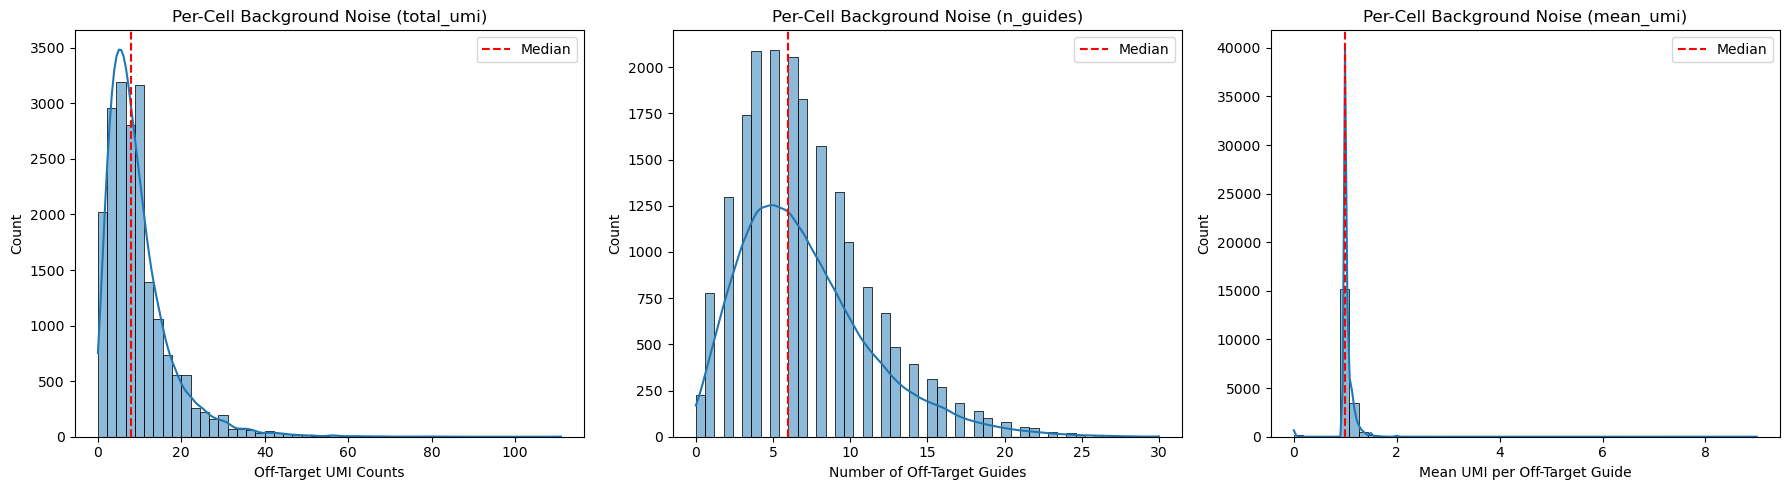

In [4]:
import scripts.qc_q2_recombination as q2

# --- Perfect singlet noise ---
per_cell_noise = q2.estimate_background_noise(adata, assignment_df, umi_df)
per_cell_noise_nguide = q2.estimate_background_noise(adata, assignment_df, umi_df, metric="n_guides")
per_cell_noise_mean = q2.estimate_background_noise(adata, assignment_df, umi_df, metric="mean_umi")

plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
sns.histplot(per_cell_noise, bins=50, kde=True)
plt.xlabel('Off-Target UMI Counts')
plt.title('Per-Cell Background Noise (total_umi)')
plt.axvline(per_cell_noise.median(), color='red', linestyle='--', label='Median')
plt.legend()

plt.subplot(1,3,2)
sns.histplot(per_cell_noise_nguide, bins=50, kde=True)
plt.xlabel('Number of Off-Target Guides')
plt.title('Per-Cell Background Noise (n_guides)')
plt.axvline(per_cell_noise_nguide.median(), color='red', linestyle='--', label='Median')
plt.legend()

plt.subplot(1,3,3)
sns.histplot(per_cell_noise_mean, bins=50, kde=True)
plt.xlabel('Mean UMI per Off-Target Guide')
plt.title('Per-Cell Background Noise (mean_umi)')
plt.axvline(per_cell_noise_mean.median(), color='red', linestyle='--', label='Median')
plt.legend()
plt.tight_layout()

%matplotlib inline
plt.show()


  --- Part A.1: Background Noise Estimation (unassigned, total_umi) ---
    Found 5,840 unassigned cells for noise estimation.
    Global Off-Target Noise Distribution (per cell):
      Mean:            6.01
      Median:          5.00
      95th Percentile: 13.00

  --- Part A.1: Background Noise Estimation (unassigned, n_guides) ---
    Found 5,840 unassigned cells for noise estimation.
    Global Off-Target Noise Distribution (per cell):
      Mean:            4.29
      Median:          4.00
      95th Percentile: 9.00

  --- Part A.1: Background Noise Estimation (unassigned, mean_umi) ---
    Found 5,840 unassigned cells for noise estimation.
    Global Off-Target Noise Distribution (per cell):
      Mean:            1.20
      Median:          1.00
      95th Percentile: 2.00


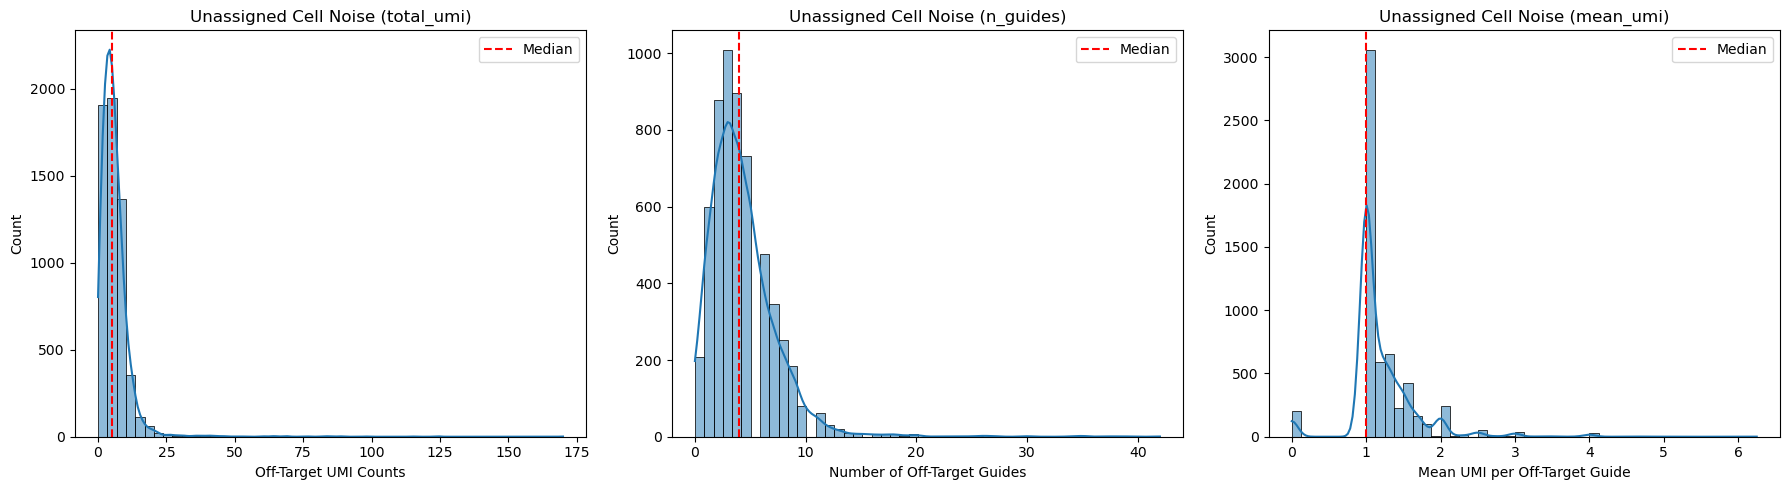

In [5]:
# --- Unassigned cell noise ---
per_cell_noise_unassigned = q2.estimate_background_noise(adata, assignment_df, umi_df, cell_category='unassigned')
per_cell_noise_nguide_unassigned = q2.estimate_background_noise(adata, assignment_df, umi_df, cell_category='unassigned', metric="n_guides")
per_cell_noise_mean_unassigned = q2.estimate_background_noise(adata, assignment_df, umi_df, cell_category='unassigned', metric="mean_umi")

plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
sns.histplot(per_cell_noise_unassigned, bins=50, kde=True)
plt.xlabel('Off-Target UMI Counts')
plt.title('Unassigned Cell Noise (total_umi)')
plt.axvline(per_cell_noise_unassigned.median(), color='red', linestyle='--', label='Median')
plt.legend()

plt.subplot(1,3,2)
sns.histplot(per_cell_noise_nguide_unassigned, bins=50, kde=True)
plt.xlabel('Number of Off-Target Guides')
plt.title('Unassigned Cell Noise (n_guides)')
plt.axvline(per_cell_noise_nguide_unassigned.median(), color='red', linestyle='--', label='Median')
plt.legend()

plt.subplot(1,3,3)
sns.histplot(per_cell_noise_mean_unassigned, bins=50, kde=True)
plt.xlabel('Mean UMI per Off-Target Guide')
plt.title('Unassigned Cell Noise (mean_umi)')
plt.axvline(per_cell_noise_mean_unassigned.median(), color='red', linestyle='--', label='Median')
plt.legend()
plt.tight_layout()
plt.show()

## Q2a (optional): Guide UMI Distributions

Estimate per-guide mean/std of log10(UMI count) from perfect singlets.
These can feed a GMM-based guide assignment refinement.

In [6]:
guide_dist_df = q2.compute_guide_umi_distributions(assignment_df, umi_df)
display(guide_dist_df.head(20))

# Save
guide_dist_df.to_csv(os.path.join(qc_out_dir, 'q2_guide_umi_distributions.csv'), index=False)
print(f"Saved guide UMI distributions: {len(guide_dist_df)} guides")


  --- Part A.2: Guide UMI Distributions ---
    Using 23,589 perfect singlets.
    Computed UMI distributions for 62 unique guides.


,guide_name,mean_log10_umi,std_log10_umi,n_cells
0,ADAMTS7_A_1,1.000089,0.464244,880
1,ADAMTS7_A_2,0.949196,0.446675,1177
2,ADAMTS7_A_3,0.952834,0.470808,967
3,CCM2_A_1,0.789340,0.407217,1631
4,CCM2_A_2,0.172780,0.232441,433
5,CCM2_A_3,0.631017,0.357385,1378
6,CEBPB_B_1,1.425430,0.462207,872
7,CEBPB_B_2,1.521622,0.503309,1128
8,CEBPB_B_3,1.258861,0.402219,585
9,FDX1_A_1,0.223887,0.249111,333


Saved guide UMI distributions: 62 guides


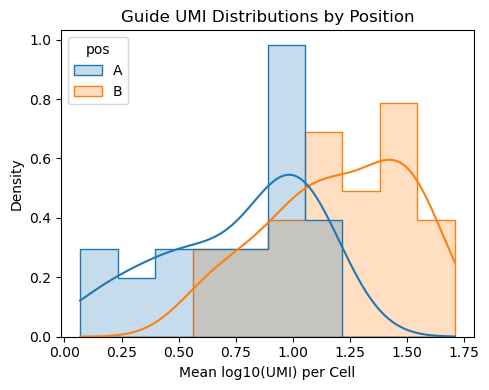

In [7]:
# plot the distributions for all guides, grouped by pos1 (*_A_*) or pos2 (*_B_*)
guide_dist_df['pos'] = guide_dist_df['guide_name'].apply(lambda x: x.split('_')[1])  # Extract posistion (A or B)

## overlayed distribution, colored by pos
plt.figure(figsize=(5,4))
sns.histplot(data=guide_dist_df, x='mean_log10_umi', hue='pos', bins=10, kde=True, element='step', stat='density')
plt.xlabel('Mean log10(UMI) per Cell')
plt.title('Guide UMI Distributions by Position')
plt.tight_layout()
plt.show()

## Q2b: gRNA-iBAR Decoupling QC

Subcategorized Decoupling Analysis for each guide unit (grna_name, ibar_seq):
* correct: if unit found in reference
* wrong_target (gRNA resolved, iBAR exists but belongs to a different target)
* ibar_missing (gRNA resolved, iBAR failed, possibly due to sequencing errors)
* novel_ibar (iBAR sequence not in the design library at all)

In [8]:
import scripts.qc_q2_recombination as q2
# Run the decoupling analysis
ref_path = cfg['paths']['grna_reference']
ref_df = pd.read_csv(ref_path)

# get umi threshold from config
umi_threshold = recomb_cfg.get('umi_thresholds', 1)  # default to 1 if not set

print(f"Using UMI threshold: {umi_threshold}")

# Note: we pass valid_bcs so it only considers GEX-positive cells
decouple_res = q2.analyze_grna_ibar_pairing(
    umi_df, 
    ref_df, 
    out_dir=qc_out_dir, 
    valid_bcs=valid_bcs,
	umi_thresholds=umi_threshold,
	save_decoupled=False,
	return_df=False
)
display(decouple_res['summary_df']) 

Using UMI threshold: [2, 5, 8, 10]

  Part B.2: gRNA-iBAR Pairing QC (Decoupling)
    Total UMI entries (with gRNA match, >= 2 UMIs): 84,251
    Cell-level decoupling rate at >= 2 UMIs:         0.0582 (1,979/33,998 cells)
    Tested 4 UMI thresholds. Use plot_decoupling_vs_umi_threshold() to visualize.


,umi_threshold,total,correct,decoupled_total,wrong_target,ibar_missing,novel_ibar,pct_correct,pct_decoupled,n_cells,n_cells_decoupled,cell_decoupling_rate
0,2,84251,81872,2379,281,2098,0,97.176295,2.823705,33998,1979,0.058209
1,5,53564,53115,449,136,313,0,99.161750,0.838250,30657,422,0.013765
2,8,45142,44888,254,115,139,0,99.437331,0.562669,28189,247,0.008762
3,10,40792,40591,201,104,97,0,99.507256,0.492744,26536,198,0.007462


    Saved plot to /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q2_decoupling_vs_umi_threshold.png


''

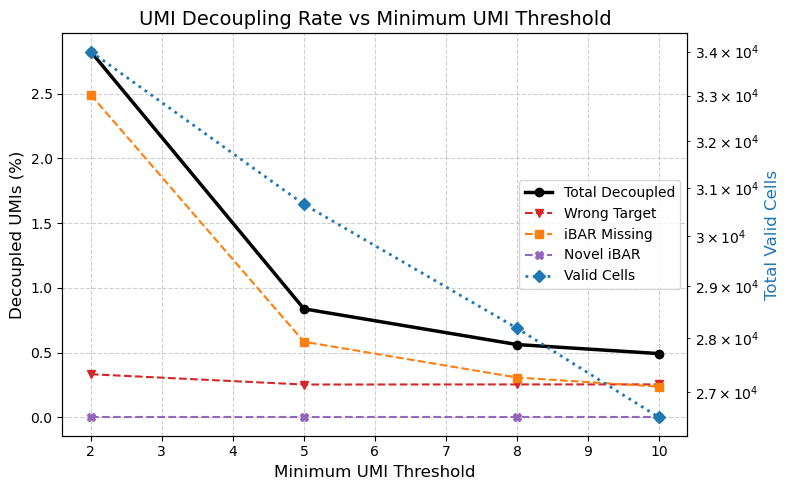

In [53]:
import scripts.qc_q2_recombination as q2
q2.plot_decoupling_vs_umi_threshold(decouple_res['summary_df'], save_path=os.path.join(qc_out_dir, 'q2_decoupling_vs_umi_threshold.png'))
;

## Q2b: Recombination Model (MLE)

In [10]:
import scripts.qc_q2_recombination as q2
moi = recomb_cfg.get('moi', 0.3)
doublet_rate = recomb_cfg.get('doublet_rate', 0.03)
print(f"Using fixed parameters: MOI={moi}, Doublet Rate={doublet_rate}")
decouple_res_fixed = q2.run_recombination_model(
	adata, 
	out_dir = qc_out_dir,
	moi=moi, 
	doublet_rate=doublet_rate, 
	r12_ratio=0.1, # cross-pos swap rate can be hard coded as r12_ratio * r_swap, using reasonable biological prior
	extended=True, 
	decoupling_rate=0.005, 
	verbose=True, 
	split_by_sample=False
)

Using fixed parameters: MOI=0.089, Doublet Rate=0.03

  --- Part B.1: Recombination MLE Model (MOI=0.089, extended=True, granular=True) ---

    MLE Results (granular, 7-category):
    Parameter      Estimate
    ────────────────────────
    d                0.0577
    s                0.1506
    r_swap1          0.0382
    r_swap2          0.0382
    r_del1           0.1177
    r_del2           0.0009
    r12              0.0038

    NLL: 55074.21  BIC: 110211.54
    Converged: True

    Category                           Observed   Expected   Residual
    ────────────────────────────────────────────────────────────────
    perfect_singlet                      19,687     21,280     -1,593
    inferred_singlet_pos1_missing         4,431      4,750       -319
    inferred_singlet_pos2_missing         1,360      1,458        -98
    multiplet_all_complete                1,820        986       +834
    multiplet_all_inferred                2,127      2,280       -153
    multiplet_mixed  

## Q2c: UMI Threshold Sweep

Re-run guide assignment at varying UMI thresholds and fit recombination parameters at each.

In [ ]:
# --- Threshold sweep ---
thresholds = [2, 5, 8, 10]
sweep_results = q2.sweep_umi_threshold(
	deduped_df=umi_df, 
	ref_df=ref_df, 
	valid_bcs=valid_bcs, 
	out_dir=qc_out_dir, 
	cfg_recomb=recomb_cfg, 
	thresholds=thresholds
)

# Display summary
sweep_df = pd.DataFrame(sweep_results)
display(sweep_df)

---
# Q3: KD Efficacy + Inferred Source Classification

Assess per-guide knockdown efficacy and classify inferred singlets.

## Q3 Setup — Classify Cells

In [11]:
import qc_q3_kd_efficacy as q3

# Full classification overview
cell_sets_full = q3.classify_cells_full(adata)

# Perfect singlets and inferred singlets
perfect_df = cell_sets_full['perfect_singlet']
inferred_df = pd.concat(
    [
        cell_sets_full['inferred_singlet_pos1_missing'],
        cell_sets_full['inferred_singlet_pos2_missing']
    ],
    axis=0
)
print(f"\nPerfect singlets: {len(perfect_df):,}")
print(f"Inferred singlets: {len(inferred_df):,}")

# ctrl_ctrl reference: ALWAYS from perfect singlets
ctrl_bcs_per_sample = {}
for sn in ['Control', 'Treatment']:
    ps = perfect_df[perfect_df['sample'] == sn]
    ctrl_bcs_per_sample[sn] = q3.get_ctrl_ctrl_cells(ps).index.tolist()
    print(f"  ctrl_ctrl ref ({sn}): {len(ctrl_bcs_per_sample[sn]):,}")


  Comprehensive Cell Classification:
    Category                          Count  % of Total
    ────────────────────────────────────────────────────
    perfect_singlet                  19,687       53.1%
    inferred_singlet_pos1_missing     4,431       11.9%
    inferred_singlet_pos2_missing     1,360        3.7%
    multiplet_all_complete            1,820        4.9%
    multiplet_all_inferred            2,127        5.7%
    multiplet_mixed                   1,821        4.9%
    unassigned                        5,840       15.7%
    ────────────────────────────────────────────────────
    TOTAL                            37,086      100.0%

Perfect singlets: 19,687
Inferred singlets: 5,791
  ctrl_ctrl ref (Control): 989
  ctrl_ctrl ref (Treatment): 1,447


In [12]:
# Sample execution inside the notebook:
ref_path = cfg['paths']['grna_reference']
ref_df = pd.read_csv(ref_path)

summary_df, full_df = q3.summarize_singlet_counts(
    adata.obs,
    split_by='sample', 
    include_recomb_multiplet=True,
    return_full_df=True,
    ref_df=ref_df
)
display(summary_df)

       Singlets Recovery Summary

[Sample Control]
  Perfect Singlets (Total: 7,928)
    - Per Construct (483/498 pairs) -> Mean: 15.9 | Median: 14.0 | Min: 0 | Max: 53
    - Per Combo     (51/51 genes) -> Mean: 155.5 | Median: 140.0 | Min: 62 | Max: 989
      [!] Missing Pairs (15): CCM2_A_1_NFKB1_B_1, LAMB2_A_2_KLF4_B_1, ZEB2_A_2_KLF2_B_3, CCM2_A_1_KLF2_B_3, LAMB2_A_2_JUN_B_1, ctrl_A_2_ctrl_B_9, ctrl_A_10_ctrl_B_8, FDX1_A_1_CEBPB_B_1, TLNRD1_A_3_KLF2_B_1, ctrl_A_2_MEF2C_B_2 ...
  Perfect + Inferred (Total: 10,099)
    - Per Construct (493/498 pairs) -> Mean: 20.3 | Median: 18.0 | Min: 0 | Max: 67
    - Per Combo     (51/51 genes) -> Mean: 198.0 | Median: 184.0 | Min: 96 | Max: 1219
      [!] Missing Pairs (5): CCM2_A_1_KLF2_B_3, ctrl_A_2_ctrl_B_9, TLNRD1_A_3_KLF2_B_1, ZEB2_A_2_KLF4_B_2, ctrl_A_7_ctrl_B_3
  Perfect + Inferred + Recomb (Total: 10,863)
    - Per Construct (494/498 pairs) -> Mean: 21.5 | Median: 19.0 | Min: 0 | Max: 67
    - Per Combo     (51/51 genes) -> Mean: 212.7 | M

,split,subset,total_cells,pairs_detected,pairs_expected,pair_mean,pair_median,pair_min,pair_max,combos_detected,combos_expected,combo_mean,combo_median,combo_min,combo_max
0,Control,Perfect Singlets,7928,483,498,15.919679,14.0,0.0,53.0,51,51,155.450980,140.0,62.0,989.0
1,Control,Perfect + Inferred,10099,493,498,20.279116,18.0,0.0,67.0,51,51,198.019608,184.0,96.0,1219.0
2,Control,Perfect + Inferred + Recomb,10863,494,498,21.538153,19.0,0.0,67.0,51,51,212.666667,194.0,108.0,1226.0
3,Treatment,Perfect Singlets,11759,488,498,23.612450,20.0,0.0,91.0,51,51,230.568627,195.0,125.0,1447.0
4,Treatment,Perfect + Inferred,15379,495,498,30.881526,27.0,0.0,104.0,51,51,301.549020,262.0,165.0,1803.0
5,Treatment,Perfect + Inferred + Recomb,16519,496,498,32.779116,28.5,0.0,117.0,51,51,323.411765,289.0,177.0,1827.0


---
## Q3a: Perfect Singlet — Gold-Standard Guide Efficacy

Establish baseline KD efficacy using perfect singlets (both positions detected).
- **Test 1 (gRNA_ctrl)**: Guides paired with ctrl partner (X_ctrl / ctrl_X)
- **Test 2 (gRNA_nonctrl)**: Guides paired with non-ctrl partner (X_Y)

Each test produces a heatmap with 4 rows: `gRNA_1, gRNA_2, gRNA_3, all`.

=== Summary Statistics ===


Min  Max   Mean  Median
sample    position                         
Control   pos1       11  109  45.78    37.0
          pos2       20  119  54.17    49.5
Treatment pos1        7  167  67.33    59.5
          pos2       32  157  75.06    69.5

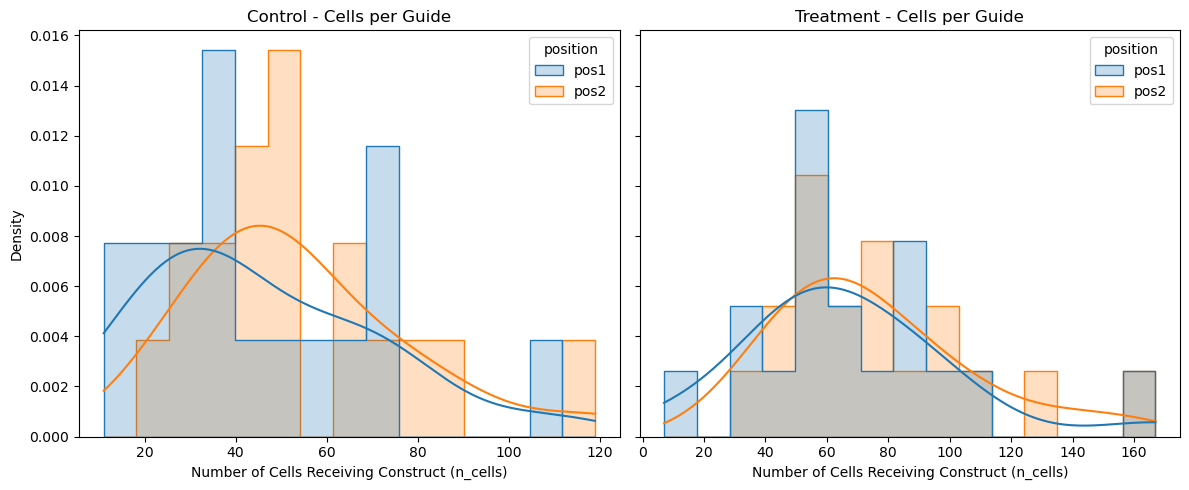

In [13]:
# --- 1. Toggle this depending on whether you want distributions per 'guide' or per 'gene' ---
group_by_gene = False

plot_data = []

# Assuming perfect_df is available from the previous step:
# perfect_df = cell_sets_full['perfect_singlet']

for sample_name in ['Control', 'Treatment']:
    # Get all perfect singlets for this sample
    sample_df = perfect_df[perfect_df['sample'] == sample_name]
    
    # 1. Extract gRNA_ctrl / ctrl_gRNA cells
    grna_groups = q3.get_grna_ctrl_cells(sample_df, group_by_gene=group_by_gene)
    
    # Store in a list for plotting
    for g in grna_groups:
        plot_data.append({
            'sample': sample_name,
            'guide_name': g['guide_name'],
            'position': g['position'],
            'n_cells': g['n_cells']
        })

plot_df = pd.DataFrame(plot_data)

# --- 2. Report Summary Statistics ---
print("=== Summary Statistics ===")
stats_df = plot_df.groupby(['sample', 'position'])['n_cells'].agg(
    Min='min',
    Max='max',
    Mean='mean',
    Median='median'
).round(2)
display(stats_df)
print("\n")


# 3. Create separate plots for Control and Treatment, overlaying pos1 and pos2
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Define a consistent palette between positions
palette = {'pos1': '#1f77b4', 'pos2': '#ff7f0e'}

for idx, sample_name in enumerate(['Control', 'Treatment']):
    ax = axes[idx]
    
    subset = plot_df[plot_df['sample'] == sample_name]
    
    if len(subset) > 0:
        sns.histplot(
            data=subset, 
            x='n_cells', 
            hue='position', 
            bins=15, 
            kde=True,
            element='step',
            stat='density', # or 'count' if you prefer raw numbers
            palette=palette,
            ax=ax
        )
    ax.set_title(f"{sample_name} - Cells per {'Gene' if group_by_gene else 'Guide'}")
    ax.set_xlabel('Number of Cells Receiving Construct (n_cells)')

%matplotlib inline
plt.tight_layout()
plt.show()

In [14]:
# === Q3a Test 1: Perfect singlet — gRNA_ctrl ===
# Per-guide (group_by_gene=False) + pooled (group_by_gene=True)

all_q3a_ctrl = []
for sample_name in ['Control', 'Treatment']:
    sample_cells = perfect_df[perfect_df['sample'] == sample_name]
    ctrl_bcs = ctrl_bcs_per_sample[sample_name]
    
    # Individual guides
    guide_groups_indiv = q3.get_grna_ctrl_cells(sample_cells, group_by_gene=False)
    mdf_indiv = q3.compute_kd_metrics(adata, guide_groups_indiv, ctrl_bcs, sample_name, min_cells=5)
    
    # Pooled per target gene
    guide_groups_pooled = q3.get_grna_ctrl_cells(sample_cells, group_by_gene=True)
    mdf_pooled = q3.compute_kd_metrics(adata, guide_groups_pooled, ctrl_bcs, sample_name, min_cells=5)
    
    if not mdf_indiv.empty:
        mdf_indiv = mdf_indiv.copy()
        mdf_indiv['guide_name_original'] = mdf_indiv['guide_name']
        mdf_indiv['guide_name'] = mdf_indiv['guide_name'].apply(
            lambda x: f"gRNA_{x.rsplit('_', 1)[-1]}" if x.rsplit('_', 1)[-1].isdigit() else x
        )
        all_q3a_ctrl.append(mdf_indiv)
    
    if not mdf_pooled.empty:
        mdf_pooled = mdf_pooled.copy()
        mdf_pooled['guide_name'] = 'all'
        mdf_pooled['guide_name_original'] = 'all'
        all_q3a_ctrl.append(mdf_pooled)

q3a_ctrl = pd.concat(all_q3a_ctrl, ignore_index=True) if all_q3a_ctrl else pd.DataFrame()
q3a_ctrl['test_mode'] = 'q3a_ctrl'

#q3.plot_heatmap(q3a_ctrl, os.path.join(qc_out_dir, 'q3a_heatmap_ctrl.png'),
#                title_suffix=' (Q3a: gRNA × ctrl)', show_pval=True)
q3.plot_de_heatmap(
    result_df=q3a_ctrl, 
    save_path=os.path.join(qc_out_dir, 'q3a_heatmap_ctrl.png'),
    title_suffix=' (Q3a: gRNA × ctrl)',
    row_key='guide_name', 
    col_key='target_gene', 
    color_key='log2FC', 
    split_by='sample', 
    annotation_key=['cpm_kd', 'n_kd_cells', 'pvalue']
)

print(f"Q3a ctrl results: {len(q3a_ctrl)} rows")
display(q3a_ctrl)

    Saved generic heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_heatmap_ctrl_control.png
    Saved generic heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_heatmap_ctrl_treatment.png
Q3a ctrl results: 96 rows


,guide_name,target_gene,position,target_combo,sample,n_kd_cells,n_ctrl_cells,cpm_kd,cpm_ctrl,pct_nonzero_kd,pct_nonzero_ctrl,log2FC,pvalue,cohens_d,note,guide_name_original,test_mode
0,gRNA_3,ZEB2_hg38,pos1,ZEB2_ctrl,Control,37,989,132.642197,199.499451,56.756757,65.015167,-0.416314,5.583747e-02,-0.298634,,ZEB2_A_3,q3a_ctrl
1,gRNA_2,ZEB2_hg38,pos1,ZEB2_ctrl,Control,62,989,178.377533,199.499451,61.290323,65.015167,-0.086027,7.298442e-01,-0.068804,,ZEB2_A_2,q3a_ctrl
2,gRNA_1,ZEB2_hg38,pos1,ZEB2_ctrl,Control,109,989,162.204330,199.499451,60.550459,65.015167,-0.185721,1.669951e-01,-0.144198,,ZEB2_A_1,q3a_ctrl
3,gRNA_3,TLNRD1_hg38,pos1,TLNRD1_ctrl,Control,75,989,16.097279,33.981033,12.000000,19.413549,-0.856074,9.051699e-02,-0.219815,,TLNRD1_A_3,q3a_ctrl
4,gRNA_1,TLNRD1_hg38,pos1,TLNRD1_ctrl,Control,60,989,14.240413,33.981033,11.666667,19.413549,-0.926085,1.103233e-01,-0.232356,,TLNRD1_A_1,q3a_ctrl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,all,CEBPB_hg38,pos2,CEBPB_ctrl,Treatment,171,1447,5.621154,4.569609,1.754386,2.211472,-0.098271,6.979761e-01,-0.013450,,all,q3a_ctrl
92,all,ZEB2_hg38,pos1,ZEB2_ctrl,Treatment,308,1447,297.052216,313.153046,70.454545,69.108500,-0.007654,8.423365e-01,-0.007108,,all,q3a_ctrl
93,all,ADAMTS7_hg38,pos1,ADAMTS7_ctrl,Treatment,202,1447,0.955510,40.848156,0.495050,18.244644,-3.791225,1.564064e-10,-0.462356,,all,q3a_ctrl
94,all,JUN_hg38,pos2,JUN_ctrl,Treatment,186,1447,77.194412,120.993935,26.344086,39.668279,-0.606801,4.277392e-04,-0.266147,,all,q3a_ctrl


In [24]:
perfect_df

,sample,species,gene_count,tscp_count,mread_count,bc1_well,bc2_well,bc3_well,sublib_index,sublibrary,...,pos2_target,inferred_pos1_grna,inferred_pos1_target,inferred_pos2_grna,inferred_pos2_target,pos1_umi,pos2_umi,n_combos,target_gene,has_grna
0_02_01_04,Control,hg38,3996,8460,16138,A2,A1,A4,0,C1,...,KLF4,unassigned,unassigned,unassigned,unassigned,36,28,1,TLNRD1_KLF4,True
0_02_01_40,Control,hg38,4177,10252,20161,A2,A1,D4,0,C1,...,ctrl,unassigned,unassigned,unassigned,unassigned,70,25,1,ctrl_ctrl,True
0_02_02_47,Control,hg38,5271,15099,30191,A2,A2,D11,0,C1,...,KLF4,unassigned,unassigned,unassigned,unassigned,1,4,1,TLNRD1_KLF4,True
0_02_02_77,Control,hg38,4105,9060,17322,A2,A2,G5,0,C1,...,KLF4,unassigned,unassigned,unassigned,unassigned,8,236,1,ZEB2_KLF4,True
0_02_03_01,Control,hg38,2756,5131,9821,A2,A3,A1,0,C1,...,CEBPB,unassigned,unassigned,unassigned,unassigned,22,35,1,ZEB2_CEBPB,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3_24_88_30,Treatment,hg38,3311,6883,13802,B12,H4,C6,3,T2,...,JUN,unassigned,unassigned,unassigned,unassigned,1,28,1,ctrl_JUN,True
3_24_88_41,Treatment,hg38,2323,4223,8358,B12,H4,D5,3,T2,...,CEBPB,unassigned,unassigned,unassigned,unassigned,1,73,1,ZEB2_CEBPB,True
3_24_89_86,Treatment,hg38,1993,3153,6121,B12,H5,H2,3,T2,...,NFKB1,unassigned,unassigned,unassigned,unassigned,1,5,1,ZEB2_NFKB1,True
3_24_90_75,Treatment,hg38,1857,2958,5756,B12,H6,G3,3,T2,...,JUN,unassigned,unassigned,unassigned,unassigned,1,9,1,TLNRD1_JUN,True


In [26]:
sample_cells = perfect_df[perfect_df['sample'] == sample_name]
sample_cells = sample_cells[nonctrl_cell_mask]
sample_cells

/local/scratch/57037815.1.broad/ipykernel_21362/3432150938.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  sample_cells = sample_cells[nonctrl_cell_mask]


,sample,species,gene_count,tscp_count,mread_count,bc1_well,bc2_well,bc3_well,sublib_index,sublibrary,...,pos2_target,inferred_pos1_grna,inferred_pos1_target,inferred_pos2_grna,inferred_pos2_target,pos1_umi,pos2_umi,n_combos,target_gene,has_grna
0_02_01_04,Control,hg38,3996,8460,16138,A2,A1,A4,0,C1,...,KLF4,unassigned,unassigned,unassigned,unassigned,36,28,1,TLNRD1_KLF4,True
0_02_01_40,Control,hg38,4177,10252,20161,A2,A1,D4,0,C1,...,ctrl,unassigned,unassigned,unassigned,unassigned,70,25,1,ctrl_ctrl,True
0_02_02_47,Control,hg38,5271,15099,30191,A2,A2,D11,0,C1,...,KLF4,unassigned,unassigned,unassigned,unassigned,1,4,1,TLNRD1_KLF4,True
0_02_02_77,Control,hg38,4105,9060,17322,A2,A2,G5,0,C1,...,KLF4,unassigned,unassigned,unassigned,unassigned,8,236,1,ZEB2_KLF4,True
0_02_03_01,Control,hg38,2756,5131,9821,A2,A3,A1,0,C1,...,CEBPB,unassigned,unassigned,unassigned,unassigned,22,35,1,ZEB2_CEBPB,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1_24_89_46,Control,hg38,2478,3994,8596,B12,H5,D10,1,C2,...,ctrl,unassigned,unassigned,unassigned,unassigned,1,7,1,ZEB2_ctrl,True
1_24_89_52,Control,hg38,2048,3156,6705,B12,H5,E4,1,C2,...,KLF2,unassigned,unassigned,unassigned,unassigned,1,4,1,ZEB2_KLF2,True
1_24_89_59,Control,hg38,2921,5255,10875,B12,H5,E11,1,C2,...,JUN,unassigned,unassigned,unassigned,unassigned,2,18,1,ctrl_JUN,True
1_24_92_61,Control,hg38,3107,6016,12403,B12,H8,F1,1,C2,...,ctrl,unassigned,unassigned,unassigned,unassigned,2,32,1,ctrl_ctrl,True


In [37]:
# === Q3a Test 2: Perfect singlet — gRNA_nonctrl ===
# exclude CCM2_TLNRD1 and CCM2_MAPK7 guides as there might be inteference/compensatory effects between these two genes (since they are in the same pathway and might have functional redundancy),
# which could confound the interpretation of individual guide effects. 
nonctrl_cell_mask = ~perfect_df['target_gene'].isin(['CCM2_TLNRD1', 'CCM2_MAPK7'])

all_q3a_nonctrl = []
for sample_name in ['Control', 'Treatment']:
    perfect_df_filterd = perfect_df[nonctrl_cell_mask]
    sample_cells = perfect_df_filterd[perfect_df_filterd['sample'] == sample_name]
    ctrl_bcs = ctrl_bcs_per_sample[sample_name]
    
    guide_groups_indiv = q3.get_grna_any_cells(sample_cells, group_by_gene=False)
    mdf_indiv = q3.compute_kd_metrics(adata, guide_groups_indiv, ctrl_bcs, sample_name, min_cells=5)
    
    guide_groups_pooled = q3.get_grna_any_cells(sample_cells, group_by_gene=True)
    mdf_pooled = q3.compute_kd_metrics(adata, guide_groups_pooled, ctrl_bcs, sample_name, min_cells=5)
    
    if not mdf_indiv.empty:
        mdf_indiv = mdf_indiv.copy()
        mdf_indiv['guide_name_original'] = mdf_indiv['guide_name']
        mdf_indiv['guide_name'] = mdf_indiv['guide_name'].apply(
            lambda x: f"gRNA_{x.rsplit('_', 1)[-1]}" if x.rsplit('_', 1)[-1].isdigit() else x
        )
        all_q3a_nonctrl.append(mdf_indiv)
    
    if not mdf_pooled.empty:
        mdf_pooled = mdf_pooled.copy()
        mdf_pooled['guide_name'] = 'all'
        all_q3a_nonctrl.append(mdf_pooled)

q3a_nonctrl = pd.concat(all_q3a_nonctrl, ignore_index=True) if all_q3a_nonctrl else pd.DataFrame()
q3a_nonctrl['test_mode'] = 'q3a_nonctrl'


#q3.plot_heatmap(q3a_nonctrl, os.path.join(qc_out_dir, 'q3a_heatmap_nonctrl.png'),
#                title_suffix=' (Q3a: gRNA × nonctrl)', show_pval=True)
q3.plot_de_heatmap(
    result_df=q3a_nonctrl, 
    save_path=os.path.join(qc_out_dir, 'q3a_heatmap_nonctrl.png'),
    title_suffix=' (Q3a: gRNA × nonctrl)', 
    row_key='guide_name', 
    col_key='target_gene', 
    color_key='log2FC', 
    split_by='sample', 
    annotation_key=['cpm_kd', 'n_kd_cells', 'pvalue']
)

print(f"Q3a nonctrl results: {len(q3a_nonctrl)} rows")
display(q3a_nonctrl)

    Saved generic heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_heatmap_nonctrl_control.png
    Saved generic heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_heatmap_nonctrl_treatment.png
Q3a nonctrl results: 96 rows


,guide_name,target_gene,position,target_combo,sample,n_kd_cells,n_ctrl_cells,cpm_kd,cpm_ctrl,pct_nonzero_kd,pct_nonzero_ctrl,log2FC,pvalue,cohens_d,note,guide_name_original,test_mode
0,gRNA_2,TLNRD1_hg38,pos1,TLNRD1_nonctrl,Control,351,989,11.878078,33.981033,5.982906,19.413549,-1.437997,6.242949e-09,-0.330773,,TLNRD1_A_2,q3a_nonctrl
1,gRNA_1,TLNRD1_hg38,pos1,TLNRD1_nonctrl,Control,238,989,25.974886,33.981033,13.025210,19.413549,-0.402006,3.788277e-02,-0.119145,,TLNRD1_A_1,q3a_nonctrl
2,gRNA_3,TLNRD1_hg38,pos1,TLNRD1_nonctrl,Control,401,989,22.508921,33.981033,13.216958,19.413549,-0.524110,6.682210e-03,-0.153701,,TLNRD1_A_3,q3a_nonctrl
3,gRNA_3,KLF4_hg38,pos2,KLF4_nonctrl,Control,247,989,0.000000,5.389360,0.000000,4.044489,-2.120652,1.323227e-03,-0.222883,,KLF4_B_3,q3a_nonctrl
4,gRNA_1,KLF4_hg38,pos2,KLF4_nonctrl,Control,282,989,0.000000,5.389360,0.000000,4.044489,-2.120652,6.049414e-04,-0.226021,,KLF4_B_1,q3a_nonctrl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,all,ZEB2_hg38,pos1,ZEB2_nonctrl,Treatment,1273,1447,289.272064,313.153046,67.478397,69.108500,-0.067446,8.463623e-02,-0.061435,,NaN,q3a_nonctrl
92,all,TLNRD1_hg38,pos1,TLNRD1_nonctrl,Treatment,1508,1447,22.042543,55.315090,10.411141,22.805805,-1.170835,2.125765e-20,-0.349546,,NaN,q3a_nonctrl
93,all,MEF2C_hg38,pos2,MEF2C_nonctrl,Treatment,1061,1447,15.014890,49.201851,6.974552,19.488597,-1.474584,3.672680e-19,-0.364316,,NaN,q3a_nonctrl
94,all,LAMB2_hg38,pos1,LAMB2_nonctrl,Treatment,971,1447,9.750256,97.869644,4.531411,37.180373,-3.005029,4.651884e-76,-0.798965,,NaN,q3a_nonctrl


In [38]:
# Save combined Q3a results
q3a_all = pd.concat([q3a_ctrl, q3a_nonctrl], ignore_index=True)
q3a_all.to_csv(os.path.join(qc_out_dir, 'q3a_guide_efficacy.csv'), index=False)
print(f"Saved Q3a: {len(q3a_all)} rows")

Saved Q3a: 192 rows


In [39]:
# Summary stats for n_cells receiving gRNA_nonctrl in Q3a
# (uses n_kd_cells from q3a_nonctrl; excludes pooled "all" rows)

q3a_nonctrl_guides = q3a_nonctrl[q3a_nonctrl["guide_name"] != "all"].copy()

nonctrl_stats_by_sample_pos = (
	q3a_nonctrl_guides
	.groupby(["sample", "position"])["n_kd_cells"]
	.agg(Min="min", Max="max", Mean="mean", Median="median", N_guides="count")
	.round(2)
)

nonctrl_stats_by_sample = (
	q3a_nonctrl_guides
	.groupby("sample")["n_kd_cells"]
	.agg(Min="min", Max="max", Mean="mean", Median="median", N_guides="count")
	.round(2)
)

print("Q3a nonctrl (per-guide) n_cells summary by sample + position")
display(nonctrl_stats_by_sample_pos)

print("\nQ3a nonctrl (per-guide) n_cells summary by sample")
display(nonctrl_stats_by_sample)

# Optional: pooled gene-level ("all") rows used in q3a_nonctrl
pooled_nonctrl = q3a_nonctrl[q3a_nonctrl["guide_name"] == "all"][["sample", "position", "target_gene", "n_kd_cells"]]
print("\nPooled gene-level rows (guide_name='all'):")
display(pooled_nonctrl.sort_values(["sample", "position", "target_gene"]))

Q3a nonctrl (per-guide) n_cells summary by sample + position


Min  Max    Mean  Median  N_guides
sample    position                                    
Control   pos1       30  401  268.50   273.5        18
          pos2      144  421  268.50   275.0        18
Treatment pos1       38  600  405.33   413.0        18
          pos2      214  622  405.33   402.0        18


Q3a nonctrl (per-guide) n_cells summary by sample


,Min,Max,Mean,Median,N_guides
sample,,,,,
Control,30,421,268.50,275.0,36
Treatment,38,622,405.33,407.5,36



Pooled gene-level rows (guide_name='all'):


,sample,position,target_gene,n_kd_cells
43,Control,pos1,ADAMTS7_hg38,850
40,Control,pos1,CCM2_hg38,831
42,Control,pos1,FDX1_hg38,695
45,Control,pos1,LAMB2_hg38,587
36,Control,pos1,TLNRD1_hg38,990
38,Control,pos1,ZEB2_hg38,880
39,Control,pos2,CEBPB_hg38,723
44,Control,pos2,JUN_hg38,872
46,Control,pos2,KLF2_hg38,724
37,Control,pos2,KLF4_hg38,744


### Flag low efficacy guides

In [40]:
# Filter per-guide significance from q3a_all:
# criterion = (pvalue < 0.05) AND (log2FC < 0) in at least one sample x test_mode combo

tmp = q3a_all[q3a_all["guide_name"] != "all"].copy()
tmp["is_sig_neg"] = (tmp["pvalue"] < 0.05) & (tmp["log2FC"] < 0)
tmp["analysis_combo"] = tmp["sample"].astype(str) + "__" + tmp["test_mode"].astype(str)

guide_key = ["target_gene", "position", "guide_name_original"]

guide_summary = (
	tmp.groupby(guide_key, as_index=False)
	.agg(
		any_sig_neg=("is_sig_neg", "any"),
		n_sig_neg_combos=("is_sig_neg", "sum"),
		n_tested_combos=("analysis_combo", "nunique"),
	)
)

guides_meet = guide_summary[guide_summary["any_sig_neg"]].copy()
guides_not_meet = guide_summary[~guide_summary["any_sig_neg"]].copy()

# Optional readable ID
guides_meet["guide_id"] = (
	guides_meet["target_gene"] + " | " + guides_meet["position"] + " | " + guides_meet["guide_name_original"]
)
guides_not_meet["guide_id"] = (
	guides_not_meet["target_gene"] + " | " + guides_not_meet["position"] + " | " + guides_not_meet["guide_name_original"]
)

display(guides_meet.sort_values(["n_sig_neg_combos"] + guide_key, ascending=[False, True, True, True]))
display(guides_not_meet.sort_values(guide_key))

,target_gene,position,guide_name_original,any_sig_neg,n_sig_neg_combos,n_tested_combos,guide_id
0,ADAMTS7_hg38,pos1,ADAMTS7_A_1,True,4,4,ADAMTS7_hg38 | pos1 | ADAMTS7_A_1
1,ADAMTS7_hg38,pos1,ADAMTS7_A_2,True,4,4,ADAMTS7_hg38 | pos1 | ADAMTS7_A_2
2,ADAMTS7_hg38,pos1,ADAMTS7_A_3,True,4,4,ADAMTS7_hg38 | pos1 | ADAMTS7_A_3
3,CCM2_hg38,pos1,CCM2_A_1,True,4,4,CCM2_hg38 | pos1 | CCM2_A_1
10,FDX1_hg38,pos1,FDX1_A_2,True,4,4,FDX1_hg38 | pos1 | FDX1_A_2
14,JUN_hg38,pos2,JUN_B_3,True,4,4,JUN_hg38 | pos2 | JUN_B_3
21,LAMB2_hg38,pos1,LAMB2_A_1,True,4,4,LAMB2_hg38 | pos1 | LAMB2_A_1
23,LAMB2_hg38,pos1,LAMB2_A_3,True,4,4,LAMB2_hg38 | pos1 | LAMB2_A_3
24,MEF2C_hg38,pos2,MEF2C_B_1,True,4,4,MEF2C_hg38 | pos2 | MEF2C_B_1
25,MEF2C_hg38,pos2,MEF2C_B_2,True,4,4,MEF2C_hg38 | pos2 | MEF2C_B_2


,target_gene,position,guide_name_original,any_sig_neg,n_sig_neg_combos,n_tested_combos,guide_id
4,CCM2_hg38,pos1,CCM2_A_2,False,0,4,CCM2_hg38 | pos1 | CCM2_A_2
5,CCM2_hg38,pos1,CCM2_A_3,False,0,4,CCM2_hg38 | pos1 | CCM2_A_3
6,CEBPB_hg38,pos2,CEBPB_B_1,False,0,4,CEBPB_hg38 | pos2 | CEBPB_B_1
8,CEBPB_hg38,pos2,CEBPB_B_3,False,0,4,CEBPB_hg38 | pos2 | CEBPB_B_3
9,FDX1_hg38,pos1,FDX1_A_1,False,0,4,FDX1_hg38 | pos1 | FDX1_A_1
22,LAMB2_hg38,pos1,LAMB2_A_2,False,0,4,LAMB2_hg38 | pos1 | LAMB2_A_2
34,ZEB2_hg38,pos1,ZEB2_A_2,False,0,4,ZEB2_hg38 | pos1 | ZEB2_A_2
35,ZEB2_hg38,pos1,ZEB2_A_3,False,0,4,ZEB2_hg38 | pos1 | ZEB2_A_3


In [41]:
len(guides_meet), len(guides_not_meet)

(28, 8)

In [42]:
# Save outputs
meet_csv = os.path.join(qc_out_dir, "q3a_guides_meet_signeg_criterion.csv")
not_csv = os.path.join(qc_out_dir, "q3a_guides_not_meet_signeg_criterion.csv")
guides_meet.sort_values(guide_key).to_csv(meet_csv, index=False)
guides_not_meet.sort_values(guide_key).to_csv(not_csv, index=False)

# Save plain-text lists

print(f"Analysis combos present: {tmp['analysis_combo'].nunique()} -> {sorted(tmp['analysis_combo'].unique())}")
print(f"Guides meeting criterion: {len(guides_meet)}")
print(f"Guides NOT meeting criterion: {len(guides_not_meet)}")
print(f"Saved:\n- {meet_csv}\n- {not_csv}")

Analysis combos present: 4 -> ['Control__q3a_ctrl', 'Control__q3a_nonctrl', 'Treatment__q3a_ctrl', 'Treatment__q3a_nonctrl']
Guides meeting criterion: 28
Guides NOT meeting criterion: 8
Saved:
- /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_guides_meet_signeg_criterion.csv
- /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_guides_not_meet_signeg_criterion.csv


In [43]:
# check the number of cells remained after excluding non-significant guides
singlet_mask = (adata.obs['combo_type'] == 'singlet') & (adata.obs['detection_status'] == 'complete')
singlet_obs = adata.obs[singlet_mask].copy()
guide_mask = singlet_obs['pos1_grna'].isin(guides_not_meet['guide_name_original']) | singlet_obs['pos2_grna'].isin(guides_not_meet['guide_name_original'])
filtered_singlet_obs = singlet_obs[~guide_mask]
print(f"Original singlet cells: {len(singlet_obs):,}")
print(f"Remaining singlet cells after excluding non-significant guides: {len(filtered_singlet_obs):,}")

Original singlet cells: 19,687
Remaining singlet cells after excluding non-significant guides: 15,179


#### Sanity check for CCM2_A_2/3

In [45]:
import qc_q3_kd_efficacy as q3
results = []
for guides in ['CCM2_A_1', 'CCM2_A_2', 'CCM2_A_3']:
    for sample_name in ['Control', 'Treatment']:
        target_bc = adata.obs.query(f'sample =="{sample_name}"').query(f'pos1_grna == "{guides}" and pos2_target == "ctrl"').index.tolist()
        ctrl_bc = adata.obs.query(f'sample =="{sample_name}"').query('pos1_target == "ctrl" and pos2_target == "ctrl"').index.tolist()
        results_df = q3.compute_custom_de(
                adata=adata,
                target_idx=target_bc,
                ctrl_idx=ctrl_bc,
                readout_gene=["CCM2", "MAPK7", "KLF2", "KLF4"]
            )
        results_df['guide'] = guides
        results_df['sample'] = sample_name
        results.append(results_df)
final_results = pd.concat(results, ignore_index=True)

In [47]:
display(final_results.query('names == "CCM2_hg38"'))

,names,scores,logfoldchanges,pvals,pvals_adj,guide,sample
3,CCM2_hg38,-1.943460,-1.329680,0.051961,1.0,CCM2_A_1,Control
7,CCM2_hg38,-2.475509,-2.371370,0.013305,1.0,CCM2_A_1,Treatment
9,CCM2_hg38,0.380297,0.151367,0.703725,1.0,CCM2_A_2,Control
15,CCM2_hg38,-0.921002,-0.674913,0.357049,1.0,CCM2_A_2,Treatment
16,CCM2_hg38,1.291297,0.474187,0.196601,1.0,CCM2_A_3,Control
23,CCM2_hg38,-0.374416,-0.317118,0.708095,1.0,CCM2_A_3,Treatment


In [48]:
display(final_results.query('names == "KLF2_hg38"'))

,names,scores,logfoldchanges,pvals,pvals_adj,guide,sample
0,KLF2_hg38,2.545389,1.558994,0.010916,1.0,CCM2_A_1,Control
4,KLF2_hg38,1.302393,2.229077,0.192782,1.0,CCM2_A_1,Treatment
11,KLF2_hg38,-0.563235,-0.534769,0.573275,1.0,CCM2_A_2,Control
13,KLF2_hg38,0.516405,1.149417,0.605572,1.0,CCM2_A_2,Treatment
17,KLF2_hg38,0.665052,0.271247,0.506017,1.0,CCM2_A_3,Control
21,KLF2_hg38,0.197370,0.969162,0.843538,1.0,CCM2_A_3,Treatment


### plot KD log2FC in gRNA_ctrl vs gRNA_nonctrl

In [49]:
# Compare per-guide log2FC between Q3a ctrl test and Q3a nonctrl test
keys = ["sample", "target_gene", "position", "guide_name", "guide_name_original"]
guides_exclude = guides_not_meet["guide_name_original"].dropna().unique().tolist()

ctrl_fc = (
	q3a_ctrl.loc[q3a_ctrl["guide_name"] != "all", keys + ["log2FC"]]
	.rename(columns={"log2FC": "log2FC_ctrl"})
)
ctrl_fc = ctrl_fc.loc[~ctrl_fc["guide_name_original"].isin(guides_exclude)]  # exclude previously identified non-significant guides

nonctrl_fc = (
	q3a_nonctrl.loc[q3a_nonctrl["guide_name"] != "all", keys + ["log2FC"]]
	.rename(columns={"log2FC": "log2FC_nonctrl"})
)
nonctrl_fc = nonctrl_fc.loc[~nonctrl_fc["guide_name_original"].isin(guides_exclude)]  # exclude previously identified non-significant guides

cmp_df = ctrl_fc.merge(nonctrl_fc, on=keys, how="inner").dropna(subset=["log2FC_ctrl", "log2FC_nonctrl"])

print(f"Matched guide rows: {len(cmp_df)}")
display(cmp_df.head())

# Correlation
r_all = cmp_df["log2FC_ctrl"].corr(cmp_df["log2FC_nonctrl"])
print(f"Pearson r (all matched guides): {r_all:.3f}")

Matched guide rows: 56


,sample,target_gene,position,guide_name,guide_name_original,log2FC_ctrl,log2FC_nonctrl
0,Control,ZEB2_hg38,pos1,gRNA_1,ZEB2_A_1,-0.185721,-0.198660
1,Control,TLNRD1_hg38,pos1,gRNA_3,TLNRD1_A_3,-0.856074,-0.524110
2,Control,TLNRD1_hg38,pos1,gRNA_1,TLNRD1_A_1,-0.926085,-0.402006
3,Control,TLNRD1_hg38,pos1,gRNA_2,TLNRD1_A_2,-4.285151,-1.437997
4,Control,JUN_hg38,pos2,gRNA_3,JUN_B_3,-3.790252,-3.289956


Pearson r (all matched guides): 0.766


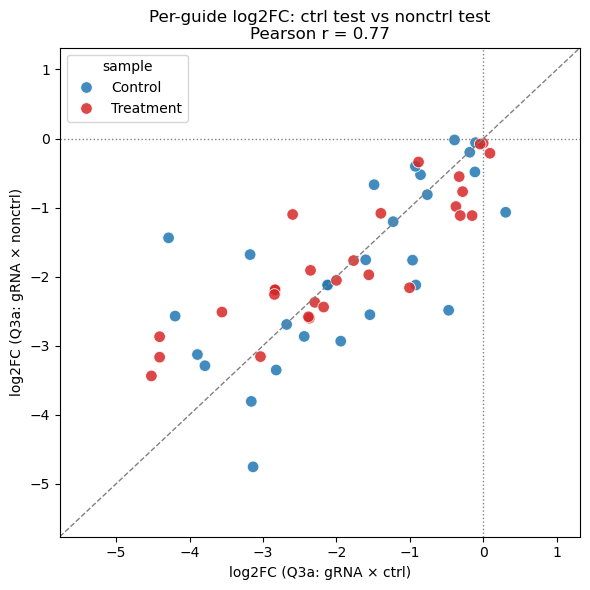

In [52]:
# Plot
%matplotlib inline
plt.figure(figsize=(6, 6))
sns.scatterplot(
	data=cmp_df,
	x="log2FC_ctrl",
	y="log2FC_nonctrl",
	hue="sample",
	palette={"Control": "#1f77b4", "Treatment": "#d62728"},
	s=70,
	alpha=0.85
)

# y=x reference line
vmin = min(cmp_df["log2FC_ctrl"].min(), cmp_df["log2FC_nonctrl"].min())
vmax = max(cmp_df["log2FC_ctrl"].max(), cmp_df["log2FC_nonctrl"].max())
pad = 0.2 * (vmax - vmin if vmax > vmin else 1.0)
lo, hi = vmin - pad, vmax + pad
plt.plot([lo, hi], [lo, hi], "--", color="gray", linewidth=1)
## add x=0 and y=0 lines
plt.axhline(0, color="gray", linestyle=":", linewidth=1)
plt.axvline(0, color="gray", linestyle=":", linewidth=1)

plt.xlim(lo, hi)
plt.ylim(lo, hi)
plt.xlabel("log2FC (Q3a: gRNA × ctrl)")
plt.ylabel("log2FC (Q3a: gRNA × nonctrl)")
plt.title(f"Per-guide log2FC: ctrl test vs nonctrl test\nPearson r = {r_all:.2f}")
plt.tight_layout()
plt.show()

---
## Q3b: Validation — Inferred Singlets + Perfect All

Validate guide efficacy in lower-power settings. All tests use **gene-pooled** groups.

Three test groups:
1. **`perfect_all`**: ALL combos (ctrl + nonctrl) in perfect singlets → maximum power baseline
2. **`detected_in_inferred`**: The guide at the DETECTED position in inferred singlets
3. **`inferred_in_inferred`**: The guide at the INFERRED position in inferred singlets

> **Note**: Q3b `perfect_all` uses ALL combos (via `get_grna_all_cells`), unlike Q3a which uses only gRNA_ctrl.

When gRNA_ctrl has < 5 cells for a target, we fall back to gRNA_all and notify.

In [ ]:
# === Q3b: Validation ===
MIN_CELLS_Q3B = 5

q3b_tests = [
    ('perfect_all',         perfect_df,  q3.get_grna_all_cells,        'Perfect singlet (all combos)'),
    ('detected_in_inferred', inferred_df, q3.get_detected_guide_cells, 'Inferred singlet (detected guide)'),
    ('inferred_in_inferred', inferred_df, q3.get_inferred_guide_cells, 'Inferred singlet (inferred guide)'),
]
# again exclude CCM2_TLNRD1 and CCM2_MAPK7 guides for the same reason as in Q3a nonctrl test
q3b_tests = [(mode, df[~df['target_gene'].isin(['CCM2_TLNRD1', 'CCM2_MAPK7'])], group_fn, desc) for mode, df, group_fn, desc in q3b_tests]

all_q3b = []
for mode_name, cell_df, group_fn, description in q3b_tests:
    print(f"\n{'='*60}")
    print(f"  Q3b: {description}")
    print(f"{'='*60}")
    
    for sample_name in ['Control', 'Treatment']:
        sample_cells = cell_df[cell_df['sample'] == sample_name]
        ctrl_bcs = ctrl_bcs_per_sample[sample_name]
        
        if len(sample_cells) == 0:
            print(f"  {sample_name}: no cells, skipping")
            continue
        
        guide_groups = group_fn(sample_cells, group_by_gene=False)
        
        # Check for low-n targets and fall back to gRNA_all
        fallback_targets = []
        for g in guide_groups:
            if g['n_cells'] < MIN_CELLS_Q3B:
                fallback_targets.append(g['target_gene'])
        
        if fallback_targets and mode_name != 'perfect_all':
            print(f"  ⚠ {sample_name}: {len(fallback_targets)} target(s) have <{MIN_CELLS_Q3B} cells "
                  f"in {mode_name}: {fallback_targets}")
            print(f"    → Falling back to gRNA_all for these targets")
            
            all_groups = q3.get_grna_all_cells(sample_cells, group_by_gene=False)
            all_groups_by_gene = {g['target_gene']: g for g in all_groups}
            
            new_groups = []
            for g in guide_groups:
                if g['target_gene'] in fallback_targets and g['target_gene'] in all_groups_by_gene:
                    fb = all_groups_by_gene[g['target_gene']].copy()
                    fb['guide_name'] = f"{g['target_gene']}_all (fallback)"
                    new_groups.append(fb)
                else:
                    new_groups.append(g)
            guide_groups = new_groups
        
        print(f"  {sample_name}: {len(sample_cells):,} cells, "
              f"{len(ctrl_bcs):,} ctrl (shared), {len(guide_groups)} gene groups")
        
        if not guide_groups:
            continue
        
        mdf = q3.compute_kd_metrics(adata, guide_groups, ctrl_bcs, sample_name, min_cells=MIN_CELLS_Q3B)
        if not mdf.empty:
            mdf['test_mode'] = mode_name
            all_q3b.append(mdf)

q3b_results = pd.concat(all_q3b, ignore_index=True) if all_q3b else pd.DataFrame()

q3b_results.to_csv(os.path.join(qc_out_dir, 'q3b_validation.csv'), index=False)
print(f"\nQ3b total: {len(q3b_results)} rows")
display(q3b_results)

In [ ]:
# --- Q3b: Combined heatmap per sample ---
import scripts.qc_q3_kd_efficacy as q3
q3.plot_de_heatmap(
    result_df=q3b_results,
    save_path=os.path.join(qc_out_dir, 'q3b_heatmap_combined.png'),
    title_suffix='',
    row_key="test_mode",       
    col_key="guide_name",     # or "guide_name"
    color_key="log2FC",
    split_by="sample",
    annotation_key=["cpm_kd", "n_kd_cells", "pvalue"]
)

In [ ]:
# --- Q3b: 3-color volcano comparison ---
PVAL_CAP = 10
import scripts.qc_q3_kd_efficacy as q3
q3.plot_volcano_comparison(
    q3b_results,
    os.path.join(qc_out_dir, 'q3b_volcano_comparison.png'),
    max_neg_log10p=PVAL_CAP
)

In [ ]:
# Compare guide-level log2FC across test modes, using perfect_all as the reference (Y-axis)
# Single figure (no split by sample), points colored by sample

ref_mode = "perfect_all"
key_cols = ["sample", "guide_name", "target_gene", "position"]

# Keep valid log2FC rows and collapse potential duplicates per guide/mode
plot_df = (
	q3b_results.dropna(subset=["log2FC"])
	.groupby(key_cols + ["test_mode"], as_index=False)["log2FC"]
	.mean()
)

ref_df = (
	plot_df[plot_df["test_mode"] == ref_mode][key_cols + ["log2FC"]]
	.rename(columns={"log2FC": "log2FC_perfect_all"})
)

modes = [m for m in plot_df["test_mode"].unique() if m != ref_mode]
if not modes:
	print("No non-reference test_mode to compare.")
else:
	n = len(modes)
	ncols = min(3, n)
	nrows = int(np.ceil(n / ncols))
	fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5.5 * nrows), sharey=True)
	axes = np.array(axes).reshape(-1)

	for i, (ax, mode_name) in enumerate(zip(axes, modes)):
		mode_df = (
			plot_df[plot_df["test_mode"] == mode_name][key_cols + ["log2FC"]]
			.rename(columns={"log2FC": "log2FC_mode"})
		)

		cmp_df = ref_df.merge(
			mode_df,
			on=key_cols,
			how="inner"
		).dropna(subset=["log2FC_perfect_all", "log2FC_mode"])

		if cmp_df.empty:
			ax.text(0.5, 0.5, "No shared guides", ha="center", va="center")
			ax.set_title(mode_name)
			ax.set_xlabel(f"log2FC ({mode_name})")
			continue

		sns.scatterplot(
			data=cmp_df,
			x="log2FC_mode",
			y="log2FC_perfect_all",
			hue="sample",
			palette={"Control": "#1f77b4", "Treatment": "#d62728"},
			alpha=0.85,
			s=55,
			ax=ax
		)

		# Annotate top 6 lowest log2FC_mode guides
		ann_df = cmp_df.nsmallest(6, "log2FC_mode")
		for _, row in ann_df.iterrows():
			ax.annotate(
				row["guide_name"],
				(row["log2FC_mode"], row["log2FC_perfect_all"]),
				xytext=(4, 4),
				textcoords="offset points",
				fontsize=8
			)

		# Reference lines
		lo = min(cmp_df["log2FC_mode"].min(), cmp_df["log2FC_perfect_all"].min())
		hi = max(cmp_df["log2FC_mode"].max(), cmp_df["log2FC_perfect_all"].max())
		pad = 0.1 * (hi - lo if hi > lo else 1.0)
		lo, hi = lo - pad, hi + pad
		ax.plot([lo, hi], [lo, hi], "--", color="gray", linewidth=1)
		ax.axhline(0, color="gray", linestyle=":", linewidth=1)
		ax.axvline(0, color="gray", linestyle=":", linewidth=1)
		ax.set_xlim(lo, hi)
		ax.set_ylim(lo, hi)

		r = cmp_df["log2FC_mode"].corr(cmp_df["log2FC_perfect_all"])
		ax.set_title(f"{mode_name}\nN={len(cmp_df)}, r={r:.2f}")
		ax.set_xlabel(f"log2FC ({mode_name})")
		ax.set_ylabel(f"log2FC ({ref_mode})")

		# Keep legend only on first subplot
		if i > 0 and ax.get_legend() is not None:
			ax.get_legend().remove()

	# Hide any unused axes
	for j in range(len(modes), len(axes)):
		axes[j].axis("off")

	fig.suptitle(f"Q3b log2FC comparison vs {ref_mode}", y=1.02, fontsize=13)
	plt.tight_layout()
	plt.show()

In [ ]:
q3b_results.head()

In [ ]:
from adjustText import adjust_text

# q3b inferred-singlet log2FC comparison:
# inferred guide (x) vs detected guide (y), all positions together

modes_to_compare = ["detected_in_inferred", "inferred_in_inferred"]
required = {"sample", "position", "guide_name", "log2FC", "test_mode"}

if not required.issubset(q3b_results.columns):
	print(f"Missing required columns: {required - set(q3b_results.columns)}")
else:
	plot_df = q3b_results.loc[
		q3b_results["test_mode"].isin(modes_to_compare)
	].dropna(subset=["log2FC"]).copy()

	if plot_df.empty:
		print("No inferred-singlet rows found in q3b_results.")
	else:
		key_cols = ["sample", "position", "guide_name"]

		wide_df = (
			plot_df.groupby(key_cols + ["test_mode"], as_index=False)["log2FC"]
			.mean()
			.pivot_table(index=key_cols, columns="test_mode", values="log2FC")
			.reset_index()
			.dropna(subset=modes_to_compare)
		)

		if wide_df.empty:
			print("No shared perturbations between detected_in_inferred and inferred_in_inferred.")
		else:
			fig, ax = plt.subplots(figsize=(5, 5))

			sns.scatterplot(
				data=wide_df,
				x="inferred_in_inferred",   # X = inferred
				y="detected_in_inferred",   # Y = detected
				hue="sample",
				palette={"Control": "#1f77b4", "Treatment": "#d62728"},
				s=55,
				alpha=0.85,
				ax=ax,
			)

			# annotate most significant guides based on log2FC in inferred_in_inferred (x-axis)
			ann = wide_df.nsmallest(5, "inferred_in_inferred")
			texts = [
				ax.text(r["inferred_in_inferred"], r["detected_in_inferred"], r["guide_name"], fontsize=8)
				for _, r in ann.iterrows()
			]
			adjust_text(
				texts,
				ax=ax,
				arrowprops=dict(arrowstyle="->", color="black", lw=0.5),
				expand_points=(1, 1),
			)

			lo = min(wide_df["inferred_in_inferred"].min(), wide_df["detected_in_inferred"].min())
			hi = max(wide_df["inferred_in_inferred"].max(), wide_df["detected_in_inferred"].max())
			pad = 0.1 * (hi - lo if hi > lo else 1.0)
			lo, hi = lo - pad, hi + pad

			ax.plot([lo, hi], [lo, hi], "--", color="gray", linewidth=1)
			ax.axhline(0, color="gray", linestyle=":", linewidth=1)
			ax.axvline(0, color="gray", linestyle=":", linewidth=1)
			ax.axvline(-1, color="gray", linestyle=":", linewidth=1)
			ax.set_xlim(lo, hi)
			ax.set_ylim(lo, hi)

			r = wide_df["inferred_in_inferred"].corr(wide_df["detected_in_inferred"])
			ax.set_xlabel("log2FC (inferred_in_inferred)")
			ax.set_ylabel("log2FC (detected_in_inferred)")
			plt.title(f"log2FC comparison: inferred_singlets")
			plt.tight_layout()
			plt.show()


### exclude cells with any other guides for the inferred targets

In [ ]:
import scripts.qc_q3_kd_efficacy as q3

## You need your raw UMI matrix
#umi_df = pd.read_csv(os.path.join(output_dir, 'grna_assignment', 'grna_umi_counts.csv'))

gene_level_kd_results = q3.filter_and_compute_inferred_gene_kd(
    adata=adata, 
    umi_df=umi_df, 
    ctrl_bcs_per_sample=ctrl_bcs_per_sample,
    backend="custom",# use the custom compute_kd_metrics backend for faster computation on selected genes; can chose "scanpy" for the standard scanpy.tl.rank_genes_groups backend (slower but more comprehensive results including transcriptome-wide FDR estimation)
	exclude_combos=['CCM2_TLNRD1', 'CCM2_MAPK7'],
	group_by_gene=False,
)

display(gene_level_kd_results.sort_values('log2FC', ascending=True).head(20))

In [ ]:
from adjustText import adjust_text
# Compare gene-level log2FC: detected (Y-axis) vs missing (X-axis), colored by sample

ref_mode = "detected"
key_cols = ["sample", "readout_gene", "guide_name"]

# Keep valid log2FC rows, collapse duplicates per guide/position
plot_df = (
	gene_level_kd_results.dropna(subset=["log2FC"])
	.groupby(key_cols + ["position"], as_index=False)[["log2FC", "pvalue"]]
	.mean()
)

ref_df = (
	plot_df[plot_df["position"] == ref_mode][key_cols + ["log2FC", "pvalue"]]
	.rename(columns={"log2FC": "log2FC_detected"})
)

modes = [m for m in plot_df["position"].unique() if m != ref_mode]
if not modes:
	print("No non-reference position to compare.")
else:
	n = len(modes)
	ncols = min(3, n)
	nrows = int(np.ceil(n / ncols))
	fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5.5 * nrows), sharey=True)
	axes = np.array(axes).reshape(-1)

	for i, (ax, mode_name) in enumerate(zip(axes, modes)):
		mode_df = (
			plot_df[plot_df["position"] == mode_name][key_cols + ["log2FC"]]
			.rename(columns={"log2FC": "log2FC_mode"})
		)

		cmp_df = ref_df.merge(
			mode_df,
			on=key_cols,
			how="inner"
		).dropna(subset=["log2FC_detected", "log2FC_mode"])

		if cmp_df.empty:
			ax.text(0.5, 0.5, "No shared genes", ha="center", va="center")
			ax.set_title(mode_name)
			ax.set_xlabel(f"log2FC ({mode_name})")
			continue

		sns.scatterplot(
			data=cmp_df,
			x="log2FC_mode",
			y="log2FC_detected",
			hue="sample",
			palette={"Control": "#1f77b4", "Treatment": "#d62728"},
			alpha=0.85,
			s=55,
			ax=ax
		)
		# NEW: Store text objects in a list
		ann_df = cmp_df.nsmallest(5, "log2FC_mode")
		#ann_df = cmp_df.nsmallest(5, "pvalue")
		texts = []
		for _, row in ann_df.iterrows():
			texts.append(
				ax.text(
					row["log2FC_mode"], 
					row["log2FC_detected"], 
					row["guide_name"], 
					fontsize=8,
				)
			)

		# NEW: Automatically adjust the text labels
		# arrowprops adds a line connecting the label to the point if it moves too far
		adjust_text(
			texts, 
			ax=ax, 
			arrowprops=dict(arrowstyle='->', color='black', lw=0.5),
			expand_points=(1, 1)
		)

		# Reference lines
		lo = min(cmp_df["log2FC_mode"].min(), cmp_df["log2FC_detected"].min())
		hi = max(cmp_df["log2FC_mode"].max(), cmp_df["log2FC_detected"].max())
		pad = 0.1 * (hi - lo if hi > lo else 1.0)
		lo, hi = lo - pad, hi + pad
		ax.plot([lo, hi], [lo, hi], "--", color="gray", linewidth=1)
		ax.axhline(0, color="gray", linestyle=":", linewidth=1)
		ax.axvline(0, color="gray", linestyle=":", linewidth=1)
		ax.set_xlim(lo, hi)
		ax.set_ylim(lo, hi)

		r = cmp_df["log2FC_mode"].corr(cmp_df["log2FC_detected"])
		ax.set_title(f"N={len(cmp_df)}, r={r:.2f}")
		ax.set_xlabel(f"log2FC ({mode_name})")
		ax.set_ylabel(f"log2FC ({ref_mode})")

		if i > 0 and ax.get_legend() is not None:
			ax.get_legend().remove()

	for j in range(len(modes), len(axes)):
		axes[j].axis("off")

	fig.suptitle(f"Gene-level log2FC comparison: {ref_mode} vs {modes[0] if modes else 'N/A'}", y=1.02, fontsize=13)
	plt.tight_layout()
	%matplotlib inline
	plt.show()


---
## Q3c: Validation - Inferred Multiplets + Perfect All

Validate cells with possible guide recombination
We expect to see high KD efficacy for the two detected guides, but close to 0 KD for the inferred guide

In [ ]:
# === Q3c: Recombination Model Validation ===
# We test whether Scenario-1 multiplet cells represent single structurally recombined constructs
# or two distinct independent co-infected vector constructs.
# If they are single recombined constructs, the "inferred missing" guides should have NO knockdown efficacy.
MIN_CELLS_Q3C = 5

print(f"\n{'='*60}")
print(f"  Q3c: Recombinant Multiplets vs Independent Co-infection")
print(f"{'='*60}")

# Exclusing CCM2_TLNRD1 and CCM2_MAPK7 targets to prevent compensatory rescue biases
exclude_combos = ['CCM2_TLNRD1', 'CCM2_MAPK7', 'TLNRD1_CCM2', 'MAPK7_CCM2']

all_q3c = []
for sample_name in ['Control', 'Treatment']:
    print(f"\nEvaluating Recombinant Multiplets for {sample_name}...")
    
    # Run the dedicated scenario-1 extraction DE method native to Q3 module
    recomb_metrics_df = q3.evaluate_recombinant_multiplets_kd(
        adata, 
        sample_name=sample_name,
        exclude_combos=exclude_combos,
        min_cells=MIN_CELLS_Q3C
    )
    
    if recomb_metrics_df is not None and not recomb_metrics_df.empty:
        recomb_metrics_df['sample'] = sample_name
        all_q3c.append(recomb_metrics_df)

if all_q3c:
    q3c_res_df = pd.concat(all_q3c, ignore_index=True)
    
    # Save the output metric tests locally
    out_q3c = os.path.join(qc_out_dir, f"q3c_recombinant_multiplet_kd_efficacy.csv")
    q3c_res_df.to_csv(out_q3c, index=False)
    print(f"\nSaved Q3c metrics to: {out_q3c}")
    
    # Quick Summary Visualization grouping by 'guide_name' (Detected vs Inferred)
    print("\nMean KD Profile (Detected vs Missing Inferred Guides):")
    summary = q3c_res_df.groupby(['sample', 'guide_name', 'position'])[['log2FC', 'cohens_d']].mean().round(3)
    display(summary)
else:
    print("\nNo Scenario-1 recombined cells met the detection criteria.")


In [ ]:
q3c_res_df.head()

In [ ]:
# Q3c: per-guide log2FC comparison (Detected vs Inferred), analogous to Q3b scatter

q3c_plot_df = q3c_res_df.dropna(subset=["log2FC", "actual_guide"]).copy()
q3c_plot_df["mode"] = np.where(
	q3c_plot_df["guide_name"].eq("Detected (Recomb)"),
	"detected",
	"inferred"
)

# Collapse pos1/pos2 and inferred_pos1/inferred_pos2 to per-guide means within sample
q3c_cmp = (
	q3c_plot_df.groupby(["sample", "actual_guide", "mode"], as_index=False)["log2FC"]
	.mean()
	.pivot_table(index=["sample", "actual_guide"], columns="mode", values="log2FC")
	.reset_index()
)

if {"detected", "inferred"}.issubset(q3c_cmp.columns):
	q3c_cmp = q3c_cmp.dropna(subset=["detected", "inferred"]).copy()
	print(f"Matched guides: {len(q3c_cmp)}")

	r_all = q3c_cmp["detected"].corr(q3c_cmp["inferred"])
	print(f"Pearson r (Detected vs Inferred): {r_all:.3f}")

	plt.figure(figsize=(5, 5))
	sns.scatterplot(
		data=q3c_cmp,
		x="inferred",
		y="detected",
		hue="sample",
		palette={"Control": "#1f77b4", "Treatment": "#d62728"},
		s=70,
		alpha=0.85
	)

	lo = min(q3c_cmp["inferred"].min(), q3c_cmp["detected"].min())
	hi = max(q3c_cmp["inferred"].max(), q3c_cmp["detected"].max())
	pad = 0.1 * (hi - lo if hi > lo else 1.0)
	lo, hi = lo - pad, hi + pad

	plt.plot([lo, hi], [lo, hi], "--", color="gray", linewidth=1)
	plt.axhline(0, color="gray", linestyle=":", linewidth=1)
	plt.axvline(0, color="gray", linestyle=":", linewidth=1)
	plt.axvline(-1, color="gray", linestyle=":", linewidth=1)
	plt.xlim(lo, hi)
	plt.ylim(lo, hi)

	ann = q3c_cmp.nsmallest(5, "inferred")
	for _, row in ann.iterrows():
		plt.annotate(
			row["actual_guide"],
			(row["inferred"], row["detected"]),
			xytext=(4, 4),
			textcoords="offset points",
			fontsize=8
		)

	plt.xlabel("log2FC (Inferred missing guide)")
	plt.ylabel("log2FC (Detected recombined guide)")
	plt.title(f"log2FC comparison: inferred_multiplet")
	plt.tight_layout()
	%matplotlib inline
	plt.show()
else:
	print("Could not build comparison: both detected and inferred modes are required.")

---
# Q4: Fitness Analysis

Compare guide-combo frequencies between pre-lentiviral library (from Q1) and single-cell data.

> **Prerequisite:** Run Q1 (`qc_q1_guideseq.py`) first to generate combo frequency tables.

In [ ]:
import scripts.qc_q4_fitness as q4

# Path to Q1-exported combo frequency table
# Update this path to your Q1 output
combo_freq_path = os.path.join(qc_out_dir, 'q1_combo_frequencies.csv')
assign_path = os.path.join(output_dir, 'grna_assignment', 'grna_cell_assignment.csv')

if os.path.exists(combo_freq_path):
    print("Found pre-lenti combo frequency table from Q1.")
else:
    print(f"WARNING: {combo_freq_path} not found.")
    print("Run Q1 first: python scripts/qc_q1_guideseq.py --config qc_config_guideseq.yaml")

In [ ]:
# --- Q4 Part A: Cell-level fitness ---
if os.path.exists(combo_freq_path):
    fitness_merged = q4.analyze_fitness(assign_path, combo_freq_path, qc_out_dir)
    if fitness_merged is not None:
        display(fitness_merged.head(10))

In [ ]:
# --- Q4 Parts B+C: Novel combos + fitness estimation ---
if os.path.exists(combo_freq_path):
    combo_freq_df = pd.read_csv(combo_freq_path)
    assign_df = pd.read_csv(assign_path)
    
    # Standardize columns
    if 'pos1_grna' not in combo_freq_df.columns and 'pos1' in combo_freq_df.columns:
        combo_freq_df = combo_freq_df.rename(columns={'pos1': 'pos1_grna', 'pos2': 'pos2_grna'})
    
    merged = q4.identify_novel_combos(assign_df, combo_freq_df, adata.obs, qc_out_dir)
    if not merged.empty:
        q4.estimate_fitness(merged, qc_out_dir)
        print("\nFitness analysis complete.")

---
## Summary

All QC outputs are saved to the `qc_analysis/` directory:
- `q2_*`: Background noise, recombination MLE, threshold sweep
- `q3_*`: Guide efficacy, custom combo DE, inferred source classification
- `q4_*`: Fitness analysis, novel combos

> Q1 outputs (bulk guide-seq) are generated separately via CLI.

---
### Custom Combo KD Analysis

Use `compute_custom_combo_de` for multi-combo × multi-gene analyses, or `compare_expression` for quick pairwise comparisons.

In [54]:
# --- Custom Combo KD Analysis ---

target_combos = ['CCM2_ctrl', 'TLNRD1_ctrl', 'CCM2_TLNRD1', 'CCM2_MAPK7']
readout_genes = ['CCM2', 'TLNRD1', 'MAP3K3', 'MAP2K5', 'MAPK7', 'KLF2', 'KLF4']

# Use perfect singlets
singlets = adata.obs[
    (adata.obs['combo_type'] == 'singlet') & 
    (adata.obs['detection_status'] == 'complete')
]

all_gene_dfs = []
all_guide_dfs = []

for sample_name in ['Control', 'Treatment']:
    sample_cells = singlets[singlets['sample'] == sample_name]
    ctrl_bcs = sample_cells[sample_cells['target_combo'] == 'ctrl_ctrl'].index.tolist()
    print(f"\n  {sample_name}: {len(sample_cells):,} singlets, {len(ctrl_bcs):,} ctrl_ctrl")
    
    gene_df, guide_df = q3.compute_custom_combo_de(
        adata, sample_cells, target_combos, readout_genes, ctrl_bcs, sample_name
    )
    all_gene_dfs.append(gene_df)
    all_guide_dfs.append(guide_df)

gene_results = pd.concat(all_gene_dfs, ignore_index=True)
guide_results = pd.concat(all_guide_dfs, ignore_index=True)

#gene_results.to_csv(os.path.join(qc_out_dir, 'q3_custom_combo_gene_level.csv'), index=False)
#guide_results.to_csv(os.path.join(qc_out_dir, 'q3_custom_combo_guide_level.csv'), index=False)

# preserve the order of target_combos and readout_genes for the heatmap
guide_results['target_combo'] = pd.Categorical(guide_results['target_combo'], categories=target_combos, ordered=True)
guide_results['readout_gene'] = pd.Categorical(guide_results['readout_gene'], categories=readout_genes, ordered=True)

#q3.plot_custom_combo_heatmap(
#    gene_results, 
#    os.path.join(qc_out_dir, 'q3_custom_combo_heatmap.png'),
#    title='Custom Combo KD (Gene-Level)',
#    show=True
#)

q3.plot_de_heatmap(
    result_df=gene_results, 
    save_path=os.path.join(qc_out_dir, 'q3_custom_combo_heatmap.png'),
    title_suffix=' (Custom Combo KD Gene-Level)',
    row_key='readout_gene', 
    col_key='target_combo', 
    color_key='log2FC', 
    split_by='sample', 
    annotation_key=['cpm_kd', 'n_kd', 'p_adj']
)

display(gene_results)


  Control: 7,928 singlets, 989 ctrl_ctrl

  Treatment: 11,759 singlets, 1,447 ctrl_ctrl


/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1100: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sample_df.groupby([row_key, col_key]).size()
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1106: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_color = sample_df.pivot_table(
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1115: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  annots[k

    Saved generic heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3_custom_combo_heatmap_control.png


/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1100: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = sample_df.groupby([row_key, col_key]).size()
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1106: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_color = sample_df.pivot_table(
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1115: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  annots[k

    Saved generic heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3_custom_combo_heatmap_treatment.png


,target_combo,readout_gene,sample,level,guide_pair,n_kd,n_ctrl,cpm_kd,cpm_ctrl,log2FC,pvalue,cohens_d
0,CCM2_ctrl,CCM2,Control,gene_combo,all,84,989,72.380066,79.790100,-0.067111,0.872856,-0.033911
1,CCM2_ctrl,TLNRD1,Control,gene_combo,all,84,989,43.468956,33.981033,0.281680,0.433805,0.102964
2,CCM2_ctrl,MAP3K3,Control,gene_combo,all,84,989,106.098122,123.202209,-0.148161,0.408074,-0.093279
3,CCM2_ctrl,MAP2K5,Control,gene_combo,all,84,989,122.795616,126.719673,0.051447,0.694365,0.036040
4,CCM2_ctrl,MAPK7,Control,gene_combo,all,84,989,16.742123,9.549706,0.698892,0.142523,0.178612
5,CCM2_ctrl,KLF2,Control,gene_combo,all,84,989,66.636002,39.702858,0.646260,0.015241,0.291501
6,CCM2_ctrl,KLF4,Control,gene_combo,all,84,989,11.010299,5.389360,0.768029,0.175497,0.174811
7,TLNRD1_ctrl,CCM2,Control,gene_combo,all,164,989,69.769188,79.790100,-0.145764,0.402120,-0.071855
8,TLNRD1_ctrl,TLNRD1,Control,gene_combo,all,164,989,12.571467,33.981033,-1.138411,0.001858,-0.275636
9,TLNRD1_ctrl,MAP3K3,Control,gene_combo,all,164,989,119.461510,123.202209,0.051515,0.503183,0.034904


### `compare_expression` — General-Purpose Comparison Utility

For quick, flexible comparisons between any two cell groups. Supports:
- `plot_type='heatmap'`, `'violin'`, or `'both'`
- `show_pval=True` for p-value annotation (Mann-Whitney U)

In [ ]:
adata.obs.query('combo_type=="multiplet" & detection_status=="inferred"')[['pos1_grna','pos1_target', 'pos2_grna', 'pos2_target', 'target_gene', 'inferred_pos1_grna', 'inferred_pos2_grna', 'target_combo']].head(10)

In [ ]:
obs = adata.obs
singlet_mask_raw = (obs['combo_type'] == 'singlet') & (obs['detection_status'] == 'complete')
inferred_multiplet_mask = (obs['combo_type'] == 'multiplet') & (obs['detection_status'] == 'inferred')
#singlet_mask = singlet_mask_raw | inferred_multiplet_mask
singlet_mask = singlet_mask_raw

target_combo = 'CCM2_TLNRD1'
control_combo = 'ctrl_ctrl'
readout_genes = ['JUN']
results_df_all = []
for sample_name in ['Control', 'Treatment']:
    combo_cells = obs[
        (obs['sample'] == sample_name) &
        singlet_mask &
        (obs['target_gene'] == target_combo)
    ].index.tolist()
    ctrl_cells = obs[
        (obs['sample'] == sample_name) &
        singlet_mask &
        (obs['target_gene'] == control_combo)
    ].index.tolist()
    results_df = q3.compare_expression(
        adata, combo_cells, ctrl_cells,
        readout_genes=readout_genes,
        test_label=target_combo,
        ctrl_label=control_combo,
        plot_type=None,
        #show_pval=True,
        #save_path=os.path.join(qc_out_dir, f'{target_combo}_vs_{control_combo}_{sample_name}.png'),
    )
    ## append sample name to results    
    results_df['sample'] = sample_name
    results_df_all.append(results_df)

display(pd.concat(results_df_all, ignore_index=True))

In [ ]:
results_df_CCM2 = []
sample_name = 'Control'
# optional: filter out cells receiving low efficacy guides
obs_all = adata.obs.copy()
low_efficacy_guides = ['CCM2_A_2', 'CCM2_A_3']
obs = obs_all.query('~pos1_grna.isin(@low_efficacy_guides)').query('~pos2_grna.isin(@low_efficacy_guides)')
for control_combo in ['ctrl_ctrl', 'ctrl_JUN']:
    for target_combo in ['CCM2_ctrl', 'CCM2_JUN', 'ctrl_JUN']:
        #if target_combo == control_combo:
        #    continue
        readout_genes = ['ICAM1', 'KLF2', 'CCM2', 'JUN']
        combo_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_gene'] == target_combo)
        ].index.tolist()
        ctrl_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_gene'] == control_combo)
        ].index.tolist()
        results_df = q3.compare_expression(
            adata, combo_cells, ctrl_cells,
            readout_genes=readout_genes,
            test_label=target_combo,
            ctrl_label=control_combo,
            plot_type=None,
            #show_pval=True,
            #save_path=os.path.join(qc_out_dir, f'{target_combo}_vs_{control_combo}_{sample_name}.png'),
        )
        results_df_CCM2.append(results_df)
ccm2_df = pd.concat(results_df_CCM2, ignore_index=True)
display(ccm2_df)

In [ ]:
%matplotlib inline
# Determine readout genes to plot
if 'readout_gene' in ccm2_df.columns and ccm2_df['readout_gene'].nunique() > 1:
    readout_genes_to_plot = ccm2_df['readout_gene'].unique().tolist()
else:
    readout_genes_to_plot = [None]

for rg in readout_genes_to_plot:
    if rg is not None:
        sub_df = ccm2_df[ccm2_df['readout_gene'] == rg].copy()
        title = f"CCM2 comparisons heatmap — {rg}"
    else:
        sub_df = ccm2_df.copy()
        title = "CCM2 comparisons heatmap"

    # Pivot matrices
    heat_log2fc = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='log2FC', aggfunc='mean')
    heat_pval = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='pvalue', aggfunc='mean')
    heat_cpm_test = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='cpm_test', aggfunc='mean')

    # Row/column side info
    row_info = sub_df.groupby('ctrl_label')[['n_ctrl', 'cpm_ctrl']].mean()
    col_info = sub_df.groupby('test_label')['n_test'].mean()

    # Mask: white out cells where test_label == ctrl_label
    mask = pd.DataFrame(False, index=heat_log2fc.index, columns=heat_log2fc.columns)
    for r in heat_log2fc.index:
        for c in heat_log2fc.columns:
            if r == c:
                mask.loc[r, c] = True

    # Cell annotations: log2FC + pvalue + cpm_test (blank for masked cells)
    annot = heat_log2fc.copy().astype(object)
    for r in heat_log2fc.index:
        for c in heat_log2fc.columns:
            if mask.loc[r, c] or pd.isna(heat_log2fc.loc[r, c]):
                annot.loc[r, c] = ""
            else:
                annot.loc[r, c] = (
                    f"log2FC={heat_log2fc.loc[r, c]:.2f}\n"
                    f"p={heat_pval.loc[r, c]:.2e}\n"
                    f"cpm_test={heat_cpm_test.loc[r, c]:.1f}"
                )

    # Axis labels with side metrics
    row_labels = [
        f"{r}\n(n_ctrl={int(round(row_info.loc[r, 'n_ctrl']))}, cpm_ctrl={row_info.loc[r, 'cpm_ctrl']:.1f})"
        for r in heat_log2fc.index
    ]
    col_labels = [
        f"{c}\n(n_test={int(round(col_info.loc[c]))})"
        for c in heat_log2fc.columns
    ]

    # Plot
    plt.figure(figsize=(4 * max(3, len(heat_log2fc.columns)), 1.4 * max(2, len(heat_log2fc.index)) + 2))
    ax = sns.heatmap(
        heat_log2fc,
        cmap="RdBu_r",
        center=0,
        mask=mask,
        annot=annot.values,
        fmt="",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "log2FC"}
    )

    ax.set_xticklabels(col_labels, rotation=30, ha="right")
    ax.set_yticklabels(row_labels, rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title)

    plt.tight_layout()
    plt.show()

In [ ]:
results_df_CCM2 = []
sample_name = 'Treatment'
# optional: filter out cells receiving low efficacy guides
obs_all = adata.obs.copy()
low_efficacy_guides = ['CCM2_A_2', 'CCM2_A_3']
obs = obs_all.query('~pos1_grna.isin(@low_efficacy_guides)').query('~pos2_grna.isin(@low_efficacy_guides)')
for control_combo in ['ctrl_ctrl', 'ctrl_JUN']:
    for target_combo in ['CCM2_ctrl', 'CCM2_JUN', 'ctrl_JUN']:
        #if target_combo == control_combo:
        #    continue
        readout_genes = ['ICAM1', 'KLF2', 'CCM2', 'JUN']
        combo_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_gene'] == target_combo)
        ].index.tolist()
        ctrl_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_gene'] == control_combo)
        ].index.tolist()
        results_df = q3.compare_expression(
            adata, combo_cells, ctrl_cells,
            readout_genes=readout_genes,
            test_label=target_combo,
            ctrl_label=control_combo,
            plot_type=None,
            #show_pval=True,
            #save_path=os.path.join(qc_out_dir, f'{target_combo}_vs_{control_combo}_{sample_name}.png'),
        )
        results_df_CCM2.append(results_df)
ccm2_df = pd.concat(results_df_CCM2, ignore_index=True)
display(ccm2_df)
%matplotlib inline
# Determine readout genes to plot
if 'readout_gene' in ccm2_df.columns and ccm2_df['readout_gene'].nunique() > 1:
    readout_genes_to_plot = ccm2_df['readout_gene'].unique().tolist()
else:
    readout_genes_to_plot = [None]

for rg in readout_genes_to_plot:
    if rg is not None:
        sub_df = ccm2_df[ccm2_df['readout_gene'] == rg].copy()
        title = f"CCM2 comparisons heatmap — {rg}"
    else:
        sub_df = ccm2_df.copy()
        title = "CCM2 comparisons heatmap"

    # Pivot matrices
    heat_log2fc = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='log2FC', aggfunc='mean')
    heat_pval = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='pvalue', aggfunc='mean')
    heat_cpm_test = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='cpm_test', aggfunc='mean')

    # Row/column side info
    row_info = sub_df.groupby('ctrl_label')[['n_ctrl', 'cpm_ctrl']].mean()
    col_info = sub_df.groupby('test_label')['n_test'].mean()

    # Mask: white out cells where test_label == ctrl_label
    mask = pd.DataFrame(False, index=heat_log2fc.index, columns=heat_log2fc.columns)
    for r in heat_log2fc.index:
        for c in heat_log2fc.columns:
            if r == c:
                mask.loc[r, c] = True

    # Cell annotations: log2FC + pvalue + cpm_test (blank for masked cells)
    annot = heat_log2fc.copy().astype(object)
    for r in heat_log2fc.index:
        for c in heat_log2fc.columns:
            if mask.loc[r, c] or pd.isna(heat_log2fc.loc[r, c]):
                annot.loc[r, c] = ""
            else:
                annot.loc[r, c] = (
                    f"log2FC={heat_log2fc.loc[r, c]:.2f}\n"
                    f"p={heat_pval.loc[r, c]:.2e}\n"
                    f"cpm_test={heat_cpm_test.loc[r, c]:.1f}"
                )

    # Axis labels with side metrics
    row_labels = [
        f"{r}\n(n_ctrl={int(round(row_info.loc[r, 'n_ctrl']))}, cpm_ctrl={row_info.loc[r, 'cpm_ctrl']:.1f})"
        for r in heat_log2fc.index
    ]
    col_labels = [
        f"{c}\n(n_test={int(round(col_info.loc[c]))})"
        for c in heat_log2fc.columns
    ]

    # Plot
    plt.figure(figsize=(4 * max(3, len(heat_log2fc.columns)), 1.4 * max(2, len(heat_log2fc.index)) + 2))
    ax = sns.heatmap(
        heat_log2fc,
        cmap="RdBu_r",
        center=0,
        mask=mask,
        annot=annot.values,
        fmt="",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "log2FC"}
    )

    ax.set_xticklabels(col_labels, rotation=30, ha="right")
    ax.set_yticklabels(row_labels, rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title)

    plt.tight_layout()
    plt.show()

#### TLNRD1?

In [ ]:
results_df_TLN = []
sample_name = 'Control'
# optional: filter out cells receiving low efficacy guides
obs_all = adata.obs.copy()
low_efficacy_guides = []
obs = obs_all.query('~pos1_grna.isin(@low_efficacy_guides)').query('~pos2_grna.isin(@low_efficacy_guides)')
for control_combo in ['ctrl_ctrl', 'ctrl_JUN']:
    for target_combo in ['TLNRD1_ctrl', 'TLNRD1_JUN', 'ctrl_JUN']:
        #if target_combo == control_combo:
        #    continue
        readout_genes = ['ICAM1', 'KLF2', 'TLNRD1', 'JUN']
        combo_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_gene'] == target_combo)
        ].index.tolist()
        ctrl_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_gene'] == control_combo)
        ].index.tolist()
        results_df = q3.compare_expression(
            adata, combo_cells, ctrl_cells,
            readout_genes=readout_genes,
            test_label=target_combo,
            ctrl_label=control_combo,
            plot_type=None,
            #show_pval=True,
            #save_path=os.path.join(qc_out_dir, f'{target_combo}_vs_{control_combo}_{sample_name}.png'),
        )
        results_df_TLN.append(results_df)
tlnr_df = pd.concat(results_df_TLN, ignore_index=True)
display(tlnr_df)

In [ ]:
%matplotlib inline
# Determine readout genes to plot
if 'readout_gene' in tlnr_df.columns and tlnr_df['readout_gene'].nunique() > 1:
    readout_genes_to_plot = tlnr_df['readout_gene'].unique().tolist()
else:
    readout_genes_to_plot = [None]

for rg in readout_genes_to_plot:
    if rg is not None:
        sub_df = tlnr_df[tlnr_df['readout_gene'] == rg].copy()
        title = f"TLNRD1 comparisons heatmap — {rg}"
    else:
        sub_df = tlnr_df.copy()
        title = "TLNRD1 comparisons heatmap"

    # Pivot matrices
    heat_log2fc = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='log2FC', aggfunc='mean')
    heat_pval = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='pvalue', aggfunc='mean')
    heat_cpm_test = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='cpm_test', aggfunc='mean')

    # Row/column side info
    row_info = sub_df.groupby('ctrl_label')[['n_ctrl', 'cpm_ctrl']].mean()
    col_info = sub_df.groupby('test_label')['n_test'].mean()

    # Mask: white out cells where test_label == ctrl_label
    mask = pd.DataFrame(False, index=heat_log2fc.index, columns=heat_log2fc.columns)
    for r in heat_log2fc.index:
        for c in heat_log2fc.columns:
            if r == c:
                mask.loc[r, c] = True

    # Cell annotations: log2FC + pvalue + cpm_test (blank for masked cells)
    annot = heat_log2fc.copy().astype(object)
    for r in heat_log2fc.index:
        for c in heat_log2fc.columns:
            if mask.loc[r, c] or pd.isna(heat_log2fc.loc[r, c]):
                annot.loc[r, c] = ""
            else:
                annot.loc[r, c] = (
                    f"log2FC={heat_log2fc.loc[r, c]:.2f}\n"
                    f"p={heat_pval.loc[r, c]:.2e}\n"
                    f"cpm_test={heat_cpm_test.loc[r, c]:.1f}"
                )

    # Axis labels with side metrics
    row_labels = [
        f"{r}\n(n_ctrl={int(round(row_info.loc[r, 'n_ctrl']))}, cpm_ctrl={row_info.loc[r, 'cpm_ctrl']:.1f})"
        for r in heat_log2fc.index
    ]
    col_labels = [
        f"{c}\n(n_test={int(round(col_info.loc[c]))})"
        for c in heat_log2fc.columns
    ]

    # Plot
    plt.figure(figsize=(4 * max(3, len(heat_log2fc.columns)), 1.4 * max(2, len(heat_log2fc.index)) + 2))
    ax = sns.heatmap(
        heat_log2fc,
        cmap="RdBu_r",
        center=0,
        mask=mask,
        annot=annot.values,
        fmt="",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "log2FC"}
    )

    ax.set_xticklabels(col_labels, rotation=30, ha="right")
    ax.set_yticklabels(row_labels, rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title)

    plt.tight_layout()
    plt.show()